# Job Listing Prioritization: Exploratory Data Analysis

PredictLeads × TripleTen externship · Jacob Colombo

## Project overview

**This is a job listing prioritization project.** A job seeker sees far more listings than they can apply to. Our goal is to rank job listings **for a given applicant**: which ones to apply to first, and why.

**Overall goal.** Find the best job search strategy, with a narrow focus and maximum depth. Prioritization is that focus: it turns the search into a ranked, explainable list.

**What this EDA is for.** Before building a prioritization model, we need to know **where to narrow down and go in depth**:
- Which **factors** should drive the ranking: the ones that actually vary between listings
- Which **time information** the data can support, since several factors depend on time
- Which **segment** (occupation group × country) has enough data for a deep, trustworthy analysis

---

## Executive summary

### At a glance

| | |
|:--|:--|
| **Goal** | Rank job listings for a given applicant: which to apply to first, and why |
| **Data** | 200,000 listings from 51,006 companies, first seen 2026-03-30 to 2026-09-30 (PredictLeads snapshot of 2026-09-30) |
| **After cleaning** | 195,801 original listings, 42,399 of them still open at the snapshot |
| **Methods** | Data cleaning · Kaplan–Meier survival analysis · factor comparisons across occupation groups · keyword text features (NLP) |
| **Recommended focus** | Computer and mathematical roles in the US *(team decision pending)* |

### Methodology

1. **Load and flatten.** Nested JSON records turned into tables, in saved parts so a crash can resume.
2. **Clean.** Dates validated, placeholder dates blanked, reposts flagged, salaries converted to one annual unit, labels unified. No listings had to be removed.
3. **Explore.** Each candidate factor measured across the largest occupation groups. Survival curves estimate how long listings stay open, counting still-open listings correctly.

### Key findings

| | Finding | Evidence | What it means for prioritization |
|:-:|:--|:--|:--|
| 1 | **Company hiring volume is the strongest signal** | Listings at companies with 20+ openings close in **14 days** (median) vs. **32** for one-off listings | Listings from high-volume employers need action first |
| 2 | **The window is short** | **28%** of listings are gone within a week; the median is gone in about **22 days** | "Still open / apply-by" is a core factor |
| 3 | **Source matters** | Company sites and LinkedIn: **17–19 days**; several hiring platforms: **28–37 days** | Source adjusts urgency |
| 4 | **Text carries signal** | Urgency wording, long descriptions, remote mentions and disclosed pay all go with listings staying open longer | NLP features are worth modeling |
| 5 | **Factors differ by field** | Remote **2–25%**, reposts **0.9–9%**, median pay **$38k–$137.5k** across occupation groups | Build the model for one segment |

### Why these numbers matter

The individual findings sound obvious: big employers move fast, and good listings go quickly. The value is in **how big the gaps are, and where they show up**. Two listings in the same field can differ more than two different fields do:
- **Company hiring volume:** a 2.3× gap in how long a listing stays open (14 vs. 32 days).
- **Source:** a 2.5× gap (15 vs. 37 days).
- **Occupation group:** only a 1.7× gap between the fastest and slowest groups (15.7 vs. 26.1 days).

That's the core result for prioritization. **What separates a listing worth applying to today from one that can wait is mostly about the listing itself, not the job title.** And every one of those traits (employer size, source, pay disclosure, wording) is known the moment a listing appears, so it can be used to predict.

The numbers also turn vague advice into rules a model can learn. "Apply early" becomes "a one-week delay costs 22–34% of your options, depending on the field." "Big companies hire fast" becomes "42% of all listings come from employers whose listings last half as long." The text results show real effects before any modeling: four simple keyword flags each shift the share of listings still open after a week by 5 to 16 percentage points. And this is with 42,399 open listings to rank on any given day.

**Why these results matter.** If these effects stack, a high-volume employer posting on its own site in a fast-moving field may give an applicant only days. A small employer on a slower hiring platform may leave a month or more. Each factor alone spans a range of two to three times. If they compound, the spread between listings is much wider, and that spread is exactly what a prioritization model ranks on. The next step, a multivariate survival model, tests whether the effects really stack or overlap. That turns these single-factor gaps into an **apply-by estimate for every individual listing,** and that's the heart of the product.


### Limits of the data

- **No seasonal advice:** only six months of history.
- **Day-of-week patterns need `posted`** (41% of listings): `first_seen` follows the crawler's schedule.
- **Fit needs a résumé,** which isn't in our data.

### Next steps

1. Confirm the segment with the team.
2. Multivariate survival model (Cox regression) to separate company volume, source, pay and text effects.
3. TF-IDF text features, trained on earlier months and tested on later ones.
4. A first prioritization score, tested against a newest-first ranking.

Full findings are in section 9.

---

### Prioritization factors (candidates)

A listing's priority combines several factors, each measured from fields in our data. We can't see applications or hires, so each factor is a proxy. The EDA keeps them all in play and shows which ones carry real, usable signal:

| Factor | Question it answers for the applicant | Measured from |
|---|---|---|
| **Still open / apply-by** | Is it still worth applying, and by when? | `first_seen_at` and `last_seen_at` (both 100% filled): how long similar listings stayed open |
| **Freshness** | Is it new enough that I'm early? | `first_seen_at`: days since the listing was first seen |
| **Competition** | How many others am I likely up against? | Reposts (the same company, title and description listed again); listings per company (`relationships.company.data.id`); open listings in the same occupation (`onet_data` with the two dates) |
| **Pay** | Is it worth an application? | `salary_data` (about 43% filled), converted to annual with `salary_time_unit` |
| **Employer intent** | Is the employer in a hurry or flexible? | `description` (82% filled) and `title`: urgency wording, remote mentions, description length |
| **Source** | Where is it posted, and how often should I check there? | `url` (100% filled): the hiring platform or company site |
| **Fit** *(not yet applicable)* | How well does it match this applicant? | Listing side: `title`; `description` (required skills, qualifications, and **years of experience required**, e.g. "3+ years"); `seniority`; `onet_data.occupation_name`; `categories`; `contract_types`; location and remote. Compared with the applicant's résumé using TF-IDF or local embeddings. |

> **Note: fit can't be applied yet.** Its listing-side fields are in our data, but it also needs the applicant's résumé, which isn't in our data. It's listed so the model has a place for it once a résumé is provided.

We combine **NLP** (what listing text says about employer intent and competition) with **time series analysis** (when listings appear and how long they stay open).

### Time context for prioritization

Some advice comes with the ranking: **when** to search (busy vs. quiet months), **how often** to check for new listings, and **how fast** to apply once a high-priority listing appears. Q2 checks which of these the data supports.

### Questions this notebook answers

| # | Question | What it decides |
|---|---|---|
| Q1 | Which factors should drive prioritization? | The factors that vary enough between listings, roles and sources to change the ranking |
| Q2 | What time information can prioritization rely on? | Apply-by estimates, check cadence, and seasonal context: which are supported |
| Q3 | Which segment do we go in depth on? | The occupation group × country with rich enough data for nuanced findings |

### What we can and can't claim

- We **can** measure when listings appear, where they're hosted, what they say, and how long they stay listed.
- We **can't** see applications or hires. A listing disappearing could mean it was filled, cancelled or moved.
- `first_seen_at` is when PredictLeads' crawler found a listing, not when the employer posted it. Q2 checks how much that matters.

### Data rules

- Print aggregates only: counts, shares, quantiles. Never `df.head()` or sample rows.
- Data stays in `data/` (git-ignored). Clear outputs before committing.

### Notebook roadmap

1. **Setup:** imports, settings, S3 connection
2. **Load raw data:** download and cache both datasets
3. **Inspect structure:** what the raw documents look like
4. **Flatten:** one row per record, built in saved parts so a crash can resume
5. **Schema:** column names, fill rates and types, written to `PROJECT_PLAN.md`
6. **Data cleaning:** types, invalid values, duplicates and reposts, salary units, missing values
7. **Prioritization EDA:** Q1 (which factors), Q2 (time information), Q3 (segment)
8. **Other feasibility checks:** language, status, contract types, tags, company match
9. **Findings: where to narrow down**

## 1. Setup

Libraries, the `.env` settings (AWS profile, S3 path) and the S3 connection.

In [1]:
# import libraries
import io
import os
from pathlib import Path

import boto3
import zstandard as zstd
from dotenv import load_dotenv, find_dotenv

import pandas as pd
import numpy as np
import time
import re

In [2]:
from dotenv import find_dotenv, dotenv_values

env_file = find_dotenv(usecwd=True)
print("found:", env_file)
print("variables:", list(dotenv_values(env_file).keys()))

found: /Users/jacobcolombo/dev/project_leads/.env
variables: ['AWS_PROFILE', 'AWS_REGION', 'S3_PATH']


In [3]:
# load aws credentials from .env file
load_dotenv(find_dotenv(usecwd=True), override=True)

s3_path = os.getenv("S3_PATH")
if not s3_path:
    raise RuntimeError("S3_PATH is not set — add `S3_PATH=s3://<bucket>/<prefix>/` on its own line in .env")

session = boto3.Session(profile_name=os.getenv("AWS_PROFILE"), region_name="us-east-2")
s3 = session.client("s3")
BUCKET, _, PREFIX = s3_path.strip().removeprefix("s3://").partition("/")

resp = s3.list_objects_v2(Bucket=BUCKET, Prefix=PREFIX)
for obj in resp.get("Contents", []):
    print(obj["Key"], round(obj["Size"] / 1e6, 1), "MB")

2026/09/30/companies_2026_09_30.jsonl.zst 252.1 MB
2026/09/30/job_openings_2026_09_30.jsonl.zst 19031.8 MB


## 2. Load raw data

Both datasets are daily snapshots in S3, stored as compressed JSON lines (`.jsonl.zst`).

- **Companies** (~252 MB compressed): small enough to load fully.
- **Job openings** (~19 GB compressed): too big for 8 GB of RAM, so we read the first 200,000 documents.

Each is cached as Parquet in `data/` after the first read, so later runs take seconds instead of about 10 minutes. Once step 4 has flattened everything, this cell skips the raw load entirely to save memory.

In [4]:
# Convert datasets to dataframes
# Loads from the parquet cache in DATA_DIR when it exists; otherwise parses the JSON once and saves parquet.
# Delete a parquet file to force a rebuild from S3.
# project root = the nearest folder up from here that holds requirements.txt
PROJECT_ROOT = next(d for d in [Path.cwd(), *Path.cwd().parents] if (d / "requirements.txt").exists())
DATA_DIR = PROJECT_ROOT / "data"  # gitignored
DATA_DIR.mkdir(exist_ok=True)

def fetch(key):
    """Download an S3 object to DATA_DIR once; return the local path."""
    local = DATA_DIR / Path(key).name
    if not local.exists():
        s3.download_file(BUCKET, key, str(local))
    return local

def stream_jsonl(key, nrows=None, chunksize=None):
    """Read a .jsonl.zst straight from S3 without downloading the whole file."""
    body = s3.get_object(Bucket=BUCKET, Key=key)["Body"]
    reader = zstd.ZstdDecompressor(max_window_size=2**31).stream_reader(body)
    text = io.TextIOWrapper(reader, encoding="utf-8")
    return pd.read_json(text, lines=True, nrows=nrows, chunksize=chunksize)

def load_cached(parquet_path, build):
    """Read parquet if cached; otherwise call build(), save it as parquet, and return it."""
    if parquet_path.exists():
        print("loading cached:", parquet_path.resolve())
        return pd.read_parquet(parquet_path)
    print("building (slow, first run only):", parquet_path.name)
    df = build()
    df.to_parquet(parquet_path, engine="pyarrow", index=False)
    print("saved:", parquet_path.resolve(), round(parquet_path.stat().st_size / 1e6, 1), "MB")
    return df

In [5]:
# Flattened tables live in DATA_DIR/flat/<table>/ as numbered parts plus a _done marker.
# Once all four are done, the raw documents aren't needed, so they aren't loaded (saves several GB).
JOBS_N = 200_000  # job-opening documents to flatten (the whole cached sample)
FLAT_DIR = DATA_DIR / "flat"
FLAT_TABLES = ["companies", "companies_included", f"job_openings_{JOBS_N}", f"job_openings_included_{JOBS_N}"]

def flat_done(name):
    return (FLAT_DIR / name / "_done").exists()

In [6]:
# Load the raw documents, unless everything is already flattened
if all(flat_done(n) for n in FLAT_TABLES):
    print("all tables already flattened: skipping the raw documents")
else:
    # companies: ~252 MB compressed — small enough to download and load fully
    companies_raw = load_cached(
        DATA_DIR / "companies_2026_09_30.parquet",
        lambda: pd.read_json(fetch(PREFIX + "companies_2026_09_30.jsonl.zst"), compression="zstd", lines=True),
    )
    # job_openings: ~19 GB compressed — too big for memory; sample it for EDA
    # (for full-file stats, use chunksize=100_000 and aggregate per chunk)
    job_openings_sample = load_cached(
        DATA_DIR / "job_openings_sample_2026_09_30.parquet",
        lambda: stream_jsonl(PREFIX + "job_openings_2026_09_30.jsonl.zst", nrows=200_000),
    )
    print("companies_raw shape:", companies_raw.shape)
    print("job_openings_sample shape:", job_openings_sample.shape)

all tables already flattened: skipping the raw documents


## 3. Inspect structure

Each line of a file is a JSON:API document with two keys: `data` (the records) and `included` (related objects the records point to, such as the company behind a job opening). This cell shows the column names and Python types only.

In [7]:
# Inspect structure: column names and the Python type of each value in the first row
for name in ["companies_raw", "job_openings_sample"]:
    if name in globals():
        df = globals()[name]
        print(name, list(df.columns))
        print(df.iloc[0].map(lambda v: type(v).__name__).to_dict())

## 4. Flatten

Turns the nested documents into ordinary tables, one row per record, with nested fields as dotted columns (for example `attributes.first_seen_at`).

Each table is built in parts of 20,000 records, and each part is saved to `data/flat/` as soon as it's done. If the kernel crashes, rerun the same cell: finished parts are skipped. A table that's fully done is never rebuilt.

### 4.1 Helpers

In [8]:
# Flatten JSON:API documents: each row holds a list of records in `data`
# and a list of related objects in `included` (referenced via relationships).
# Each table is flattened in parts of PART_ROWS records, and each part is saved as soon as it's built.
# If the kernel dies, rerun the cell: finished parts are skipped. Delete DATA_DIR/flat/<table>/ to rebuild.
import gc

PART_ROWS = 20_000

def flatten_to_parts(df, col, name, dedupe=False):
    """Flatten df[col] into DATA_DIR/flat/<name>/part_NNNN.pkl, then write a _done marker.
    dedupe=True keeps the first (type, id) only, *before* flattening, to save memory."""
    out_dir = FLAT_DIR / name
    if flat_done(name):
        print(f"{name}: already flattened")
        return
    out_dir.mkdir(parents=True, exist_ok=True)
    existing = {f.name for f in out_dir.glob("part_*.pkl")}
    start, seen, buf, kept, part_no = time.time(), set(), [], 0, 0
    skip = "part_0000.pkl" in existing

    def flush():
        nonlocal buf, part_no, skip
        if buf:
            pd.json_normalize(buf).to_pickle(out_dir / f"part_{part_no:04d}.pkl")
            print(f"  {name}: part {part_no} saved, {kept:,} records so far, {time.time() - start:.0f}s", flush=True)
        buf, part_no = [], part_no + 1
        skip = f"part_{part_no:04d}.pkl" in existing
        gc.collect()

    for batch in df[col]:
        # lists come back as numpy arrays when loaded from the parquet cache
        if not isinstance(batch, (list, np.ndarray)):
            continue
        for r in batch:
            if dedupe:
                key = (r.get("type"), r.get("id"))
                if key in seen:
                    continue
                seen.add(key)
            kept += 1
            if not skip:
                buf.append(r)
            if kept % PART_ROWS == 0:
                flush()
    flush()
    (out_dir / "_done").touch()
    print(f"{name}: {kept:,} records in {time.time() - start:.0f}s")

In [9]:
# Read flattened tables back, one part at a time
def map_parts(name, fn):
    """Apply fn to each saved part and concatenate the results, one part in memory at a time."""
    parts = sorted((FLAT_DIR / name).glob("part_*.pkl"))
    return pd.concat([fn(pd.read_pickle(f)) for f in parts], ignore_index=True)

def load_flat(name, columns):
    """Load only the listed columns of a flattened table (missing columns come back empty)."""
    return map_parts(name, lambda d: d.reindex(columns=columns))

### 4.2 Companies

In [10]:
# Flatten companies (records in `data`)
if not flat_done("companies"):
    flatten_to_parts(companies_raw, "data", "companies")

### 4.3 Companies: related objects

In [11]:
# Flatten the companies file's related objects (`included`), duplicates removed
if not flat_done("companies_included"):
    flatten_to_parts(companies_raw, "included", "companies_included", dedupe=True)

### 4.4 Job openings

In [12]:
# Flatten job openings (records in `data`)
if not flat_done(f"job_openings_{JOBS_N}"):
    flatten_to_parts(job_openings_sample.head(JOBS_N), "data", f"job_openings_{JOBS_N}")

### 4.5 Job openings: related objects

In [13]:
# Flatten the job openings file's related objects (`included`), duplicates removed
if not flat_done(f"job_openings_included_{JOBS_N}"):
    flatten_to_parts(job_openings_sample.head(JOBS_N), "included", f"job_openings_included_{JOBS_N}", dedupe=True)

## 5. Schema

Writes a `df.info()`-style summary of every flattened table (column names, non-null counts, dtypes) into `PROJECT_PLAN.md`. It only rewrites the file when something changed.

In [14]:
# Write a df.info()-style schema for each flattened table into PROJECT_PLAN.md
# Column names, non-null counts and dtypes only, never data values. Reads one part at a time.
PLAN_PATH = PROJECT_ROOT / "PROJECT_PLAN.md"

def schema_md(name, table, note=""):
    n, non_null, dtypes = 0, pd.Series(dtype="int64"), {}
    for f in sorted((FLAT_DIR / table).glob("part_*.pkl")):
        part = pd.read_pickle(f)
        n += len(part)
        non_null = non_null.add(part.notna().sum(), fill_value=0)
        for col, dtype in part.dtypes.items():
            dtypes[col] = dtype if dtypes.get(col, dtype) == dtype else "object"
        del part
    lines = [
        f"#### `{name}`: {n:,} rows × {len(dtypes)} columns{note}",
        "",
        "| # | Column | Non-null | Null % | Dtype |",
        "|---|---|---|---|---|",
    ]
    for i, (col, dtype) in enumerate(dtypes.items()):
        nn = int(non_null.get(col, 0))
        null_pct = 100 * (1 - nn / n) if n else 0
        lines.append(f"| {i} | `{col}` | {nn:,} | {null_pct:.1f}% | {dtype} |")
    return "\n".join(lines)

In [15]:
# Build the four schemas and write them into PROJECT_PLAN.md, only if they changed
jobs_note = f" (from the first {JOBS_N:,} job-opening documents)"
sections = [
    schema_md("companies", "companies"),
    schema_md("companies_included", "companies_included", " (duplicates removed by type and id)"),
    schema_md("job_openings", f"job_openings_{JOBS_N}", jobs_note),
    schema_md("job_openings_included", f"job_openings_included_{JOBS_N}", jobs_note + ", duplicates removed by type and id"),
]
body = "\n\n".join(sections)
generated = f"_Generated {pd.Timestamp.now():%Y-%m-%d %H:%M} from the 2026-09-30 snapshot._\n\n" + body

plan = PLAN_PATH.read_text()
pattern = r"(<!-- schema:start -->\n).*?(\n<!-- schema:end -->)"
current = re.search(pattern, plan, flags=re.S)
if not current:
    raise RuntimeError("schema markers not found in PROJECT_PLAN.md")
if body in current.group(0):
    print("schemas unchanged, PROJECT_PLAN.md left as is")
else:
    PLAN_PATH.write_text(re.sub(pattern, lambda m: m.group(1) + generated + m.group(2), plan, flags=re.S))
    print("wrote schemas for", len(sections), "tables to", PLAN_PATH.resolve())

schemas unchanged, PROJECT_PLAN.md left as is


## 6. Data cleaning

The timing analysis is only as good as its dates, so cleaning comes before any analysis. Every step shows its results as small summary tables (counts, shares, quantiles and category labels, never rows) and records how many rows it touched. Step 6.7 shows the full cleaning report for the write-up.

| Step | What | Why |
|---|---|---|
| 6.1 | Build a lean table: keep the columns we need, clean description text into features | The full table with descriptions doesn't fit in memory |
| 6.2 | Fix types and standardize categories | Dates arrive as text; labels vary in case and spacing |
| 6.3 | Remove or blank impossible dates | A posting can't close before it opens |
| 6.4 | Remove duplicate records and flag reposts | Reposts would double-count postings and distort how long they last |
| 6.5 | Convert salaries to one annual unit and blank outliers | Hourly and yearly salaries can't be compared directly |
| 6.6 | Missing-value summary | Shows which analyses each field can support |
| 6.7 | Cleaning report | The audit trail |

### 6.0 Chart style

One style for every chart in the notebook: a light surface, recessive grid, thin marks, and a fixed color order (blue, orange, aqua, yellow) so a color always means the same thing within a chart. Charts show aggregates only.

In [16]:
# 6.0a Chart colors and style shared by every chart below
import matplotlib.pyplot as plt

BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"  # categorical order: never reorder
INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#c9c8c2", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "font.size": 10.5, "lines.linewidth": 2, "legend.frameon": False, "figure.dpi": 110,
})

In [17]:
# 6.0b Chart helpers
def bar_h(ax, s, title, xlabel, fmt="{:,.0f}", color=BLUE):
    """Horizontal bars, largest at the top, each value labelled at the bar end."""
    s = s.dropna().sort_values()
    ax.barh([str(i)[:42] for i in s.index], s.values, color=color, height=0.65)
    for y, v in enumerate(s.values):
        ax.text(v, y, " " + fmt.format(v), va="center", color=INK_2, fontsize=8.5)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    ax.margins(x=0.18)

def finish():
    plt.tight_layout()
    plt.show()

*No output: this cell only sets the chart style.*

### 6.1 Lean table and text cleaning

Reads the flattened job openings one part at a time and keeps only the columns the analysis needs. Descriptions are too big to keep in memory, so each one is cleaned (HTML tags removed, entities decoded, whitespace collapsed) and turned into features:

- `has_desc`, `has_html`, `desc_words`
- `mentions_remote` and `urgency`: first NLP signals
- `desc_hash`: a fingerprint of the cleaned text, used to find reposts in step 6.4

The posting `url` is reduced to its **source**: the hiring platform (for example Greenhouse or Workday), a job board, or the company's own site. Full URLs aren't kept.

The result is cached in `data/clean/`, so this slow step runs once. If the cached table is missing a column the code now expects, it's rebuilt.

In [18]:
# 6.1a Paths and the columns we keep
import hashlib
import html

CLEAN_DIR = DATA_DIR / "clean"
CLEAN_DIR.mkdir(exist_ok=True)
LEAN_PATH = CLEAN_DIR / f"job_openings_lean_{JOBS_N}.pkl"

COLS = {  # flattened column -> short name
    "id": "id",
    "relationships.company.data.id": "company_id",
    "attributes.title": "title",
    "attributes.first_seen_at": "first_seen",
    "attributes.last_seen_at": "last_seen",
    "attributes.posted_at": "posted",
    "attributes.status": "status",
    "attributes.seniority": "seniority",
    "attributes.language": "language",
    "attributes.onet_data.family": "occupation_group",
    "attributes.onet_data.occupation_name": "occupation",
    "attributes.salary_data.salary_low_usd": "salary_low_usd",
    "attributes.salary_data.salary_high_usd": "salary_high_usd",
    "attributes.salary_data.salary_time_unit": "salary_unit",
    "attributes.contract_types": "contract_types",
    "attributes.location_data": "location_data",
    "attributes.tags": "tags",
    "attributes.categories": "categories",
}

In [19]:
# 6.1b Patterns used to clean and flag description text
TAG_RE = re.compile(r"<[^>]+>")
URGENT_RE = r"\burgent|\bimmediate(?:ly)?\b|\basap\b"
from urllib.parse import urlparse

In [20]:
# 6.1c Posting source from the url domain
# Hiring platforms (applicant tracking systems) and job boards, matched against the url's domain
ATS = {"greenhouse.io": "Greenhouse", "lever.co": "Lever", "myworkdayjobs.com": "Workday", "workday.com": "Workday",
       "smartrecruiters.com": "SmartRecruiters", "icims.com": "iCIMS", "ashbyhq.com": "Ashby", "bamboohr.com": "BambooHR",
       "jobvite.com": "Jobvite", "taleo.net": "Taleo", "successfactors": "SuccessFactors", "recruitee.com": "Recruitee",
       "workable.com": "Workable", "breezy.hr": "Breezy", "applytojob.com": "JazzHR", "paylocity.com": "Paylocity",
       "ultipro.com": "UKG", "ukg.com": "UKG", "adp.com": "ADP", "dayforcehcm.com": "Dayforce", "oraclecloud.com": "Oracle",
       "teamtailor.com": "Teamtailor", "personio": "Personio", "rippling.com": "Rippling", "jobs.lever": "Lever"}
BOARDS = {"indeed.com": "Indeed", "linkedin.com": "LinkedIn", "ziprecruiter.com": "ZipRecruiter",
          "glassdoor.com": "Glassdoor", "monster.com": "Monster", "dice.com": "Dice", "builtin.com": "Built In",
          "wellfound.com": "Wellfound"}

def source_of(url):
    """(source_type, platform) from the url's domain; company sites aren't named."""
    if not isinstance(url, str):
        return ("(missing)", None)
    host = urlparse(url).netloc.lower()
    for table, kind in ((ATS, "hiring platform"), (BOARDS, "job board")):
        for key, name in table.items():
            if key in host:
                return (kind, name)
    return ("company site / other", None)

In [21]:
# 6.1d Text and location helpers
def clean_text(s):
    """Strip HTML tags, decode entities like &amp;, collapse whitespace."""
    if not isinstance(s, str):
        return ""
    return " ".join(html.unescape(TAG_RE.sub(" ", s)).split())

def first_country(locs):
    """Country of the first location; postings can list several."""
    if isinstance(locs, (list, np.ndarray)) and len(locs) and isinstance(locs[0], dict):
        return locs[0].get("country")
    return None

In [22]:
# 6.1e Turn one flattened part into lean rows
def lean_part(d):
    out = d.reindex(columns=list(COLS)).rename(columns=COLS)
    raw = d.reindex(columns=["attributes.description"])["attributes.description"]
    text = raw.map(clean_text)
    out["has_desc"] = text.str.len() > 0
    out["has_html"] = raw.fillna("").str.contains(TAG_RE)
    out["desc_words"] = text.str.split().str.len()
    out["mentions_remote"] = (out["title"].fillna("") + " " + text).str.contains(r"\bremote\b", case=False)
    out["urgency"] = text.str.contains(URGENT_RE, case=False)
    out["desc_hash"] = text.str.lower().str[:1000].map(lambda t: hashlib.md5(t.encode()).hexdigest() if t else None)
    out["n_locations"] = out["location_data"].map(lambda v: len(v) if isinstance(v, (list, np.ndarray)) else 0)
    out["country"] = out.pop("location_data").map(first_country)
    src = d.reindex(columns=["attributes.url"])["attributes.url"].map(source_of)
    out["source_type"] = src.str[0]
    out["platform"] = src.str[1]
    return out

In [23]:
# 6.1f Build the lean table, or load it from the cache
LEAN_COLS = list(COLS.values()) + ["source_type", "platform"]
jobs = pd.read_pickle(LEAN_PATH) if LEAN_PATH.exists() else None
if jobs is not None:
    jobs = jobs.rename(columns={"family": "occupation_group"})  # caches built before the rename
if jobs is not None and set(LEAN_COLS) - {"location_data"} <= set(jobs.columns):
    print("loaded cached lean table:", jobs.shape)
else:
    for v in ("companies_raw", "job_openings_sample"):
        globals().pop(v, None)  # the raw documents aren't needed past this point
    gc.collect()
    start = time.time()
    jobs = map_parts(f"job_openings_{JOBS_N}", lean_part)
    jobs.to_pickle(LEAN_PATH)
    print(f"built lean table {jobs.shape} in {time.time() - start:.0f}s")

companies = load_flat("companies", ["id"])

loaded cached lean table: (200000, 27)


In [24]:
# 6.1g Helpers for the cleaning report and summary tables
from IPython.display import display

report = []  # cleaning audit trail: one row per action, shown in 6.7
def log(step, action, n):
    report.append({"step": step, "action": action, "rows": int(n)})

def show(title, df):
    """Print a heading, then display a summary table. Aggregates only, never rows."""
    print(f"\n{title}")
    display(df)

def distinct(s):
    try:
        return s.nunique()
    except TypeError:  # list-valued columns (tags, categories, contract_types)
        return np.nan

In [25]:
# 6.1h Summary tables
log("6.1", "rows in lean table", len(jobs))

show(f"Lean table: {len(jobs):,} rows × {jobs.shape[1]} columns", pd.DataFrame({
    "dtype": jobs.dtypes.astype(str),
    "non-null %": (100 * jobs.notna().mean()).round(1),
    "distinct values": {c: distinct(jobs[c]) for c in jobs.columns},
}))

show("Text cleaning results", pd.DataFrame({"share of postings": {
    "has a description": jobs.has_desc.mean(),
    "description contained HTML (now stripped)": jobs.has_html.mean(),
    "mentions remote": jobs.mentions_remote.mean(),
    "urgency wording": jobs.urgency.mean(),
}}).round(3))

show("Description length in words (postings with a description)",
     jobs.desc_words[jobs.has_desc].describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(0).to_frame("words"))

show("Posting source (from the url domain)", pd.DataFrame({
    "postings": jobs.source_type.value_counts(),
    "share": jobs.source_type.value_counts(normalize=True).round(3),
}))


Lean table: 200,000 rows × 27 columns


,dtype,non-null %,distinct values
id,object,100.0,200000.0
company_id,object,100.0,51006.0
title,object,100.0,140321.0
first_seen,object,100.0,160817.0
last_seen,object,100.0,167930.0
posted,object,43.8,20820.0
status,object,64.5,1.0
seniority,object,100.0,11.0
language,object,95.4,33.0
occupation_group,object,100.0,23.0



Text cleaning results


,share of postings
has a description,0.823
description contained HTML (now stripped),0.003
mentions remote,0.108
urgency wording,0.094



Description length in words (postings with a description)


,words
count,164510.0
mean,639.0
std,343.0
min,1.0
10%,233.0
25%,403.0
50%,607.0
75%,839.0
90%,1077.0
max,5828.0



Posting source (from the url domain)


,postings,share
source_type,,
company site / other,121342,0.607
hiring platform,58074,0.290
job board,20584,0.103


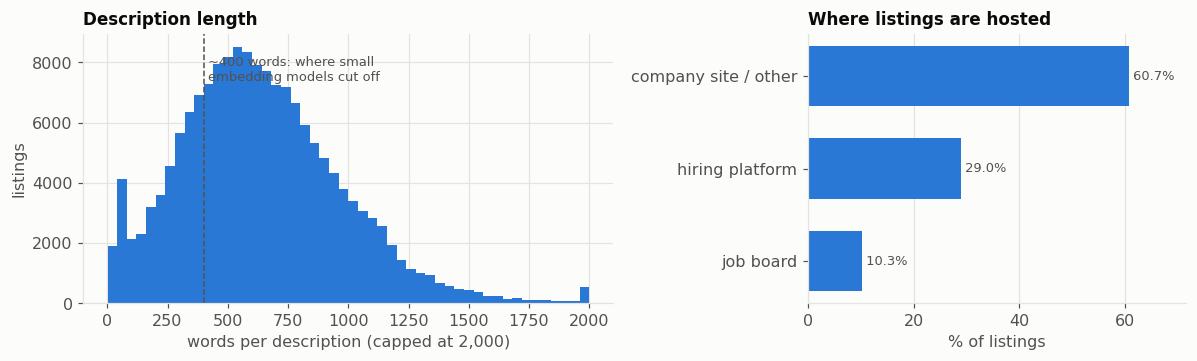

In [26]:
# 6.1i Charts: description length and where listings are hosted
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1.4, 1]})
ax1.hist(jobs.desc_words[jobs.has_desc].clip(upper=2000), bins=50, color=BLUE)
ax1.axvline(400, color=INK_2, ls="--", lw=1)
ax1.text(420, ax1.get_ylim()[1] * 0.92, "~400 words: where small\nembedding models cut off", color=INK_2, fontsize=8.5, va="top")
ax1.set(title="Description length", xlabel="words per description (capped at 2,000)", ylabel="listings")
bar_h(ax2, 100 * jobs.source_type.value_counts(normalize=True), "Where listings are hosted", "% of listings", "{:.1f}%")
finish()

**What the data shows**
- **200,000 listings from 51,006 companies.** Every listing has a title, both timeline dates and an occupation group.
- **Descriptions are already clean.** 82.3% of listings have one, and only 0.3% contained HTML. PredictLeads supplies mostly plain text.
- **Descriptions are long:** the median is 607 words, and three quarters run past ~400 words. Any later embedding work needs chunking, not truncation.
- **Most listings live on company sites (60.7%),** then hiring platforms (29.0%) and job boards (10.3%, mostly LinkedIn).
- **Two fields have a single value:** `status` and `country`. Both are explained in 6.2 and Q3.
- First text signals: 10.8% of listings mention remote work, and 9.4% use urgency wording.

### 6.2 Types and standard categories

- Dates become UTC timestamps. Text that won't parse becomes missing, and we count it.
- Category labels (status, seniority, language, salary unit) are trimmed and lowercased, so "Full time" and "full time " count as one value.
- `contract_types` labels are unified, so "full_time" and "full time" count as one value.
- `title_norm`, a lowercased title with whitespace collapsed, is used for duplicate detection.

In [27]:
# 6.2a Parse dates
date_rows = {}
for col in ["first_seen", "last_seen", "posted"]:
    had_value = jobs[col].notna()
    jobs[col] = pd.to_datetime(jobs[col], utc=True, errors="coerce")
    unparseable = (had_value & jobs[col].isna()).sum()
    log("6.2", f"{col}: unparseable dates set to missing", unparseable)
    date_rows[col] = {"had a value": had_value.sum(), "parsed": jobs[col].notna().sum(),
                      "unparseable → missing": unparseable,
                      "earliest": jobs[col].min(), "latest": jobs[col].max()}
show("Date parsing", pd.DataFrame(date_rows).T)


Date parsing


,had a value,parsed,unparseable → missing,earliest,latest
first_seen,200000,200000,0,2026-03-30 14:11:56+00:00,2026-09-30 14:07:23+00:00
last_seen,200000,200000,0,2026-03-30 14:45:32+00:00,2026-09-30 14:07:53+00:00
posted,87583,87583,0,1969-12-30 23:00:00+00:00,2026-09-29 22:00:00+00:00


In [28]:
# 6.2b Standardize category labels
cat_rows, label_tables = {}, {}
for col in ["status", "seniority", "language", "salary_unit"]:
    before = jobs[col].nunique()
    jobs[col] = jobs[col].astype("string").str.strip().str.lower()
    log("6.2", f"{col}: distinct labels merged by trimming and lowercasing", before - jobs[col].nunique())
    cat_rows[col] = {"labels before": before, "labels after": jobs[col].nunique(),
                     "merged": before - jobs[col].nunique(), "missing %": round(100 * jobs[col].isna().mean(), 1)}
    label_tables[col] = jobs[col].fillna("(missing)").value_counts().head(8)
show("Category labels: trimmed and lowercased", pd.DataFrame(cat_rows).T)
for col, counts in label_tables.items():
    show(f"Top {col} labels after cleaning", pd.DataFrame({"postings": counts, "share": (counts / len(jobs)).round(3)}))


Category labels: trimmed and lowercased


,labels before,labels after,merged,missing %
status,1.0,1.0,0.0,35.5
seniority,11.0,11.0,0.0,0.0
language,33.0,33.0,0.0,4.6
salary_unit,5.0,5.0,0.0,56.9



Top status labels after cleaning


,postings,share
status,,
closed,129097,0.645
(missing),70903,0.355



Top seniority labels after cleaning


,postings,share
seniority,,
mid_senior,105955,0.53
junior,60269,0.301
manager,25247,0.126
director,5669,0.028
head,1116,0.006
vice_president,945,0.005
c_level,454,0.002
founder,109,0.001



Top language labels after cleaning


,postings,share
language,,
en,184889,0.924
(missing),9228,0.046
de,1367,0.007
es,1328,0.007
fr,999,0.005
it,547,0.003
nl,345,0.002
pt,274,0.001



Top salary_unit labels after cleaning


,postings,share
salary_unit,,
(missing),113846,0.569
hour,48215,0.241
year,35120,0.176
month,1346,0.007
week,1229,0.006
day,244,0.001


In [29]:
# 6.2c Normalized titles and unified contract_types labels
jobs["title_norm"] = jobs["title"].astype("string").str.lower().str.split().str.join(" ")

# contract_types mixes spellings of the same label ("full_time" and "full time"); unify them
def norm_labels(v):
    items = v if isinstance(v, (list, tuple, np.ndarray)) else []
    return sorted({str(x).strip().lower().replace("_", " ").replace("-", " ") for x in items})
before = jobs.contract_types.explode().nunique()
jobs["contract_types"] = jobs.contract_types.map(norm_labels)
after = jobs.contract_types.explode().nunique()
log("6.2", "contract_types: distinct labels merged (underscores, case, spacing)", before - after)
show("contract_types labels", pd.DataFrame({"labels": {"before": before, "after": after, "merged": before - after}}))


contract_types labels


,labels
before,106
after,101
merged,5


**What the data shows**
- **Every date parsed.** `first_seen` runs from 2026-03-30 to 2026-09-30: exactly six months before the snapshot. The file appears to keep a rolling six-month window.
- **`posted` has placeholder values:** the earliest is 1969-12-30, a Unix-epoch default. Step 6.3 blanks it. Its timestamps sit at 22:00 or 23:00 UTC, which is midnight in Central European time, so `posted` is probably a local date. Q2c checks what that means for weekdays.
- **`status` is never "open".** It's "closed" (64.5%) or missing (35.5%), so it can't identify live listings. `last_seen` is the only way to tell (see 6.7).
- **Labels were already consistent** (nothing merged by trimming or case), except `contract_types`, which mixed "full_time" and "full time". It's unified above.
- **Seniority is mostly mid/senior (53%) and junior (30%).** **English covers 92.4%** of listings.
- **Hourly pay is the most common salary unit:** 24.1% of all listings, ahead of yearly at 17.6%.

### 6.3 Invalid dates

- **No `first_seen` or `last_seen`:** the posting can't be placed in time, so it's removed.
- **`last_seen` before `first_seen`:** impossible, so it's removed.
- **Dates after the snapshot (2026-09-30):** impossible, so they're removed.
- **`posted` more than a day after `first_seen`, or before 2000:** the crawler can't find a posting before it exists, so the `posted` value is blanked. The posting itself stays.

In [30]:
# 6.3a Remove impossible timelines
SNAPSHOT = pd.Timestamp("2026-09-30", tz="UTC")
END_OF_SNAPSHOT = SNAPSHOT + pd.Timedelta(days=1)
rows_before = len(jobs)

rules = {
    "missing first_seen or last_seen": jobs.first_seen.isna() | jobs.last_seen.isna(),
    "last_seen before first_seen": jobs.last_seen < jobs.first_seen,
    "dates after the snapshot": (jobs.first_seen > END_OF_SNAPSHOT) | (jobs.last_seen > END_OF_SNAPSHOT),
}
rule_rows, bad = {}, pd.Series(False, index=jobs.index)
for name, mask in rules.items():
    new = (mask & ~bad).sum()  # count each row once, under the first rule it fails
    log("6.3", f"removed, {name}", new)
    rule_rows[name] = {"rows": new, "share of rows": round(new / rows_before, 4), "action": "removed"}
    bad |= mask
jobs = jobs[~bad].copy()

In [31]:
# 6.3b Blank implausible posted dates
bad_posted = (jobs.posted > jobs.first_seen + pd.Timedelta(days=1)) | (jobs.posted < pd.Timestamp("2000-01-01", tz="UTC"))
jobs.loc[bad_posted, "posted"] = pd.NaT
log("6.3", "posted blanked (after first_seen or before 2000)", bad_posted.sum())
rule_rows["posted after first_seen or before 2000"] = {
    "rows": bad_posted.sum(), "share of rows": round(bad_posted.sum() / rows_before, 4), "action": "posted blanked"}

In [32]:
# 6.3c Summary tables
show("Date validity rules", pd.DataFrame(rule_rows).T)
show("Rows before and after", pd.DataFrame({"rows": {"before": rows_before, "removed": rows_before - len(jobs),
                                                     "after": len(jobs)}}))
days_open = (jobs.last_seen - jobs.first_seen).dt.total_seconds() / 86400
show("Days between first_seen and last_seen (after cleaning)",
     days_open.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(1).to_frame("days"))


Date validity rules


,rows,share of rows,action
missing first_seen or last_seen,0,0.0,removed
last_seen before first_seen,0,0.0,removed
dates after the snapshot,0,0.0,removed
posted after first_seen or before 2000,5454,0.0273,posted blanked



Rows before and after


,rows
before,200000
removed,0
after,200000



Days between first_seen and last_seen (after cleaning)


,days
count,200000.0
mean,29.8
std,35.3
min,0.0
10%,0.0
25%,6.0
50%,16.4
75%,39.4
90%,78.5
max,183.7


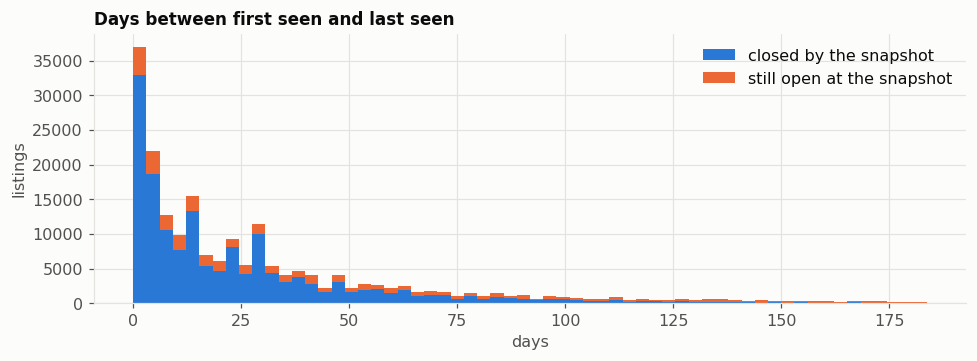

In [33]:
# 6.3d Chart: days between first seen and last seen
still_open = (SNAPSHOT - jobs.last_seen).dt.days <= 2
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.hist([days_open[~still_open], days_open[still_open]], bins=60, stacked=True, color=[BLUE, ORANGE],
        label=["closed by the snapshot", "still open at the snapshot"])
ax.set(title="Days between first seen and last seen", xlabel="days", ylabel="listings")
ax.legend()
finish()

**What the data shows**
- **No impossible timelines:** no missing dates, no listing that closes before it opens, nothing after the snapshot. PredictLeads' timeline fields are clean.
- **5,454 `posted` values (2.7%) were blanked:** epoch placeholders, or a date more than a day after the crawler first saw the listing.
- **Raw durations:** median 16.4 days; a quarter last 6 days or less, and 10% were seen on a single day. The maximum, 183.7 days, equals the six-month window, so long durations are capped by the data.
- These raw durations treat still-open listings as if they had ended. Q1b corrects for that with survival curves.

### 6.4 Duplicates and reposts

- **Exact duplicates:** the same record `id` twice. Keep one.
- **Reposts:** the same company, the same normalized title and the same description text (by fingerprint), under different ids. These aren't removed. The earliest copy is kept as the original and later ones get `is_repost = True`.

Reposts matter for timing: an employer reposting a job suggests it didn't fill. The EDA uses originals only, so each job is counted once, and reposts may become a signal of their own later.

In [34]:
# 6.4a Drop exact duplicate ids; flag reposts of the same job
rows_before = len(jobs)
dup_id = jobs.duplicated("id")
log("6.4", "removed, duplicate id", dup_id.sum())
jobs = jobs[~dup_id].copy()

jobs = jobs.sort_values("first_seen")
key = ["company_id", "title_norm", "desc_hash"]
has_key = jobs[key].notna().all(axis=1)
jobs["is_repost"] = has_key & jobs.duplicated(key)
log("6.4", "flagged as repost (kept, excluded from the EDA tables)", jobs.is_repost.sum())
log("6.4", "postings without a description, can't be checked for reposts", (~has_key).sum())

In [35]:
# 6.4b Summary tables
show("Duplicates and reposts", pd.DataFrame({"rows": {
    "before": rows_before,
    "exact duplicate ids (removed)": dup_id.sum(),
    "after": len(jobs),
    "reposts (flagged, kept)": jobs.is_repost.sum(),
    "originals": (~jobs.is_repost).sum(),
    "no description, can't be checked": (~has_key).sum(),
}}))
group_sizes = jobs[has_key].groupby(key).size()
show("How many times the same job is listed (original + reposts)",
     group_sizes.value_counts().sort_index().head(10).rename_axis("listings per job").to_frame("jobs"))
show("Repost rate by source type", jobs.groupby("source_type").is_repost.mean().round(3).to_frame("repost rate"))


Duplicates and reposts


,rows
before,200000
exact duplicate ids (removed),0
after,200000
"reposts (flagged, kept)",4199
originals,195801
"no description, can't be checked",35490



How many times the same job is listed (original + reposts)


,jobs
listings per job,
1,158405
2,1248
3,291
4,114
5,60
6,38
7,39
8,20
9,19



Repost rate by source type


,repost rate
source_type,
company site / other,0.018
hiring platform,0.005
job board,0.084


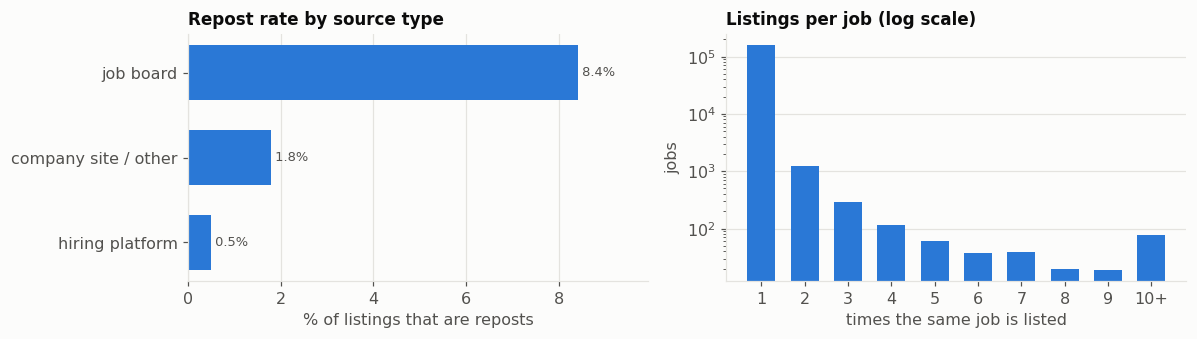

In [36]:
# 6.4c Charts: repost rate and listings per job
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.2))
bar_h(ax1, 100 * jobs.groupby("source_type").is_repost.mean(), "Repost rate by source type", "% of listings that are reposts", "{:.1f}%")
sizes = group_sizes.clip(upper=10).value_counts().sort_index()
ax2.bar([str(int(k)) if k < 10 else "10+" for k in sizes.index], sizes.values, color=BLUE, width=0.65)
ax2.set_yscale("log")
ax2.set(title="Listings per job (log scale)", xlabel="times the same job is listed", ylabel="jobs")
ax2.grid(axis="x", visible=False)
finish()

**What the data shows**
- **No duplicate ids.** PredictLeads already de-duplicates records.
- **4,199 reposts (2.1%)** are the same job listed again under a new id. They're flagged and left out of the EDA tables. That's a lower bound: 35,490 listings without a description can't be checked.
- **Most jobs are listed once,** but a long tail is relisted 10 or more times.
- **Job boards repost far more** (8.4% of their listings) than company sites (1.8%) or hiring platforms (0.5%). That fits boards re-advertising the same job.

### 6.5 Salary to one annual unit

Salaries come as low and high values in USD, each with a time unit (hour, day, week, month or year). We take the midpoint and convert it to a yearly figure, using 2,080 work hours, 260 workdays, 52 weeks or 12 months per year. A missing or unrecognized unit, or a result outside $10k–$1M a year, is set to missing and counted.

In [37]:
# 6.5a Salary time units
PER_YEAR = {"hour": 2080, "day": 260, "week": 52, "month": 12, "year": 1}

def unit_factor(u):
    if pd.isna(u):
        return np.nan
    return next((f for k, f in PER_YEAR.items() if k in u), np.nan)

mid = jobs[["salary_low_usd", "salary_high_usd"]].mean(axis=1)
factor = jobs.salary_unit.map(unit_factor)
unit_counts = jobs.loc[mid.notna(), "salary_unit"].fillna("(missing)").value_counts()
show("Salary units (postings with a salary)", pd.DataFrame({
    "postings": unit_counts,
    "× per year": unit_counts.index.map(lambda u: unit_factor(u) if u != "(missing)" else np.nan),
}).fillna({"× per year": "not recognized"}))


Salary units (postings with a salary)


,postings,× per year
salary_unit,,
hour,48215,2080
year,35120,1
month,1346,12
week,1229,52
day,244,260


In [38]:
# 6.5b Annualize salaries; blank outliers
log("6.5", "salary present but unit missing or not recognized", (mid.notna() & factor.isna()).sum())
annual = mid * factor
outlier = ~annual.between(10_000, 1_000_000) & annual.notna()
jobs["salary_annual_usd"] = annual.mask(outlier)
log("6.5", "annual salary outside $10k-$1M, blanked", outlier.sum())

In [39]:
# 6.5c Summary tables
show("Salary cleaning", pd.DataFrame({"postings": {
    "salary present": mid.notna().sum(),
    "unit missing or not recognized": (mid.notna() & factor.isna()).sum(),
    "annualized": annual.notna().sum(),
    "outside $10k–$1M (blanked)": outlier.sum(),
    "usable annual salary": jobs.salary_annual_usd.notna().sum(),
}}))
q = [0.1, 0.25, 0.5, 0.75, 0.9]
show("Annual salary (USD) quantiles, before and after removing outliers", pd.DataFrame({
    "before": annual.quantile(q), "after": jobs.salary_annual_usd.quantile(q)}).round(-2))


Salary cleaning


,postings
salary present,86154
unit missing or not recognized,0
annualized,86154
outside $10k–$1M (blanked),14
usable annual salary,86140



Annual salary (USD) quantiles, before and after removing outliers


,before,after
0.10,35100.0,35100.0
0.25,41600.0,41600.0
0.50,60600.0,60500.0
0.75,104000.0,104000.0
0.90,162000.0,162000.0


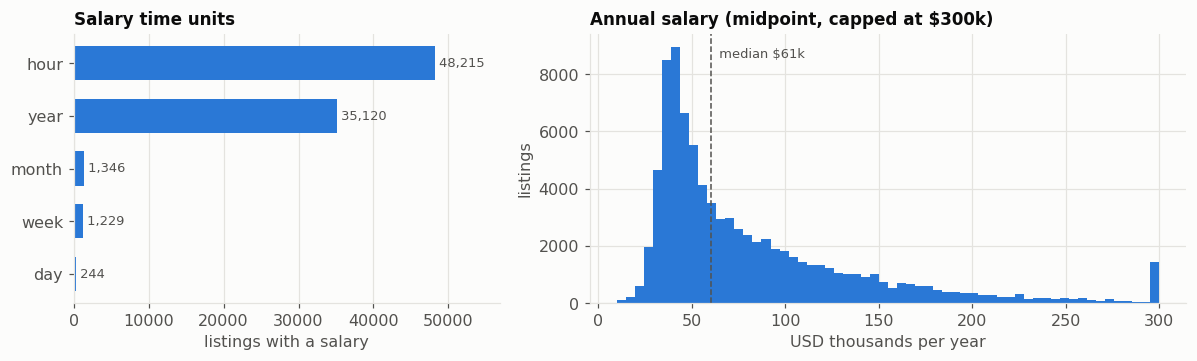

In [40]:
# 6.5d Charts: salary units and annual salary
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1, 1.4]})
bar_h(ax1, unit_counts, "Salary time units", "listings with a salary")
pay = jobs.salary_annual_usd.dropna().clip(upper=300_000)
ax2.hist(pay / 1000, bins=60, color=BLUE)
ax2.axvline(pay.median() / 1000, color=INK_2, ls="--", lw=1)
ax2.text(pay.median() / 1000, ax2.get_ylim()[1] * 0.95, f"  median ${pay.median() / 1000:.0f}k", color=INK_2, fontsize=8.5, va="top")
ax2.set(title="Annual salary (midpoint, capped at $300k)", xlabel="USD thousands per year", ylabel="listings")
finish()

**What the data shows**
- **86,154 listings (43.1%) disclose pay,** and every one has a recognized unit, so nothing was lost to unit problems.
- **Hourly pay is the most common unit** (48,215 listings), then yearly (35,120). Annualizing assumes 2,080 work hours a year, which overstates pay for part-time roles.
- **Only 14 outliers** fell outside $10k–$1M a year.
- **The median midpoint is about $60.5k a year,** with an interquartile range of $41.6k–$104k. The histogram shows two humps, one for hourly jobs and one for salaried roles.

### 6.6 Missing values

The share of postings missing each field we plan to use. It shows what each analysis can rely on. For example, the crawler-vs-employer check in 7.1 only uses postings that have `posted`.


Missing values (after cleaning)


,missing %,available rows
platform,60.7,78658.0
posted,58.9,82129.0
salary_annual_usd,56.9,86140.0
status,35.5,129097.0
description,17.7,164510.0
country,8.4,183222.0
language,4.6,190772.0
title,0.0,200000.0
first_seen,0.0,200000.0
last_seen,0.0,200000.0


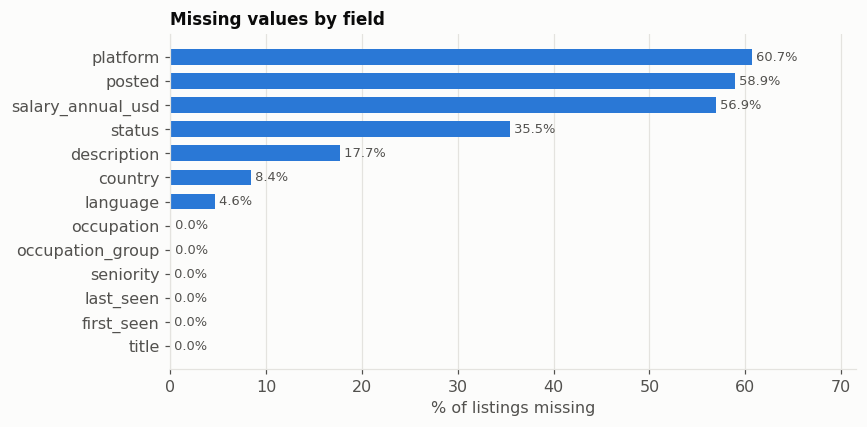

In [41]:
# 6.6 Missing-value summary for the fields the analysis uses
fields = ["title", "first_seen", "last_seen", "posted", "status", "seniority", "language",
          "occupation_group", "occupation", "salary_annual_usd", "country", "platform"]
missing = pd.DataFrame({"missing %": 100 * jobs[fields].isna().mean(), "available rows": jobs[fields].notna().sum()})
missing.loc["description"] = [100 * (~jobs.has_desc).mean(), jobs.has_desc.sum()]
show("Missing values (after cleaning)", missing.round(1).sort_values("missing %", ascending=False))

fig, ax = plt.subplots(figsize=(8, 4))
bar_h(ax, missing["missing %"], "Missing values by field", "% of listings missing", "{:.1f}%")
finish()

**What the data shows**
- **The timeline fields** (`first_seen`, `last_seen`) **plus title, seniority and occupation group are essentially complete.** Every prioritization factor built on them works for every listing.
- **`platform` is missing for 60.7%,** which is expected: company sites have no platform.
- **`posted` (58.9% missing) and salary (56.9% missing) are the weak fields.** Any factor using them covers under half the listings.
- **`country` is missing for 8.4%.** Every listing that has one is in the United States (Q3).

### 6.7 Cleaning report and derived timing columns

The full audit trail, then the columns every timing analysis uses:

- `live`: seen within 2 days of the snapshot, so still open. Its lifespan is *censored* (we don't know when it ends yet), which the survival analysis in Q1b accounts for.
- `days_open`: from `first_seen` to `last_seen`
- `month`: the month the posting was first seen

`jo` holds the originals (no reposts), which is the table the EDA uses.

In [42]:
# 6.7a Derived timing columns and the analysis table (originals only)
LIVE_DAYS = 2
jobs["live"] = (SNAPSHOT - jobs.last_seen).dt.days <= LIVE_DAYS
jobs["days_open"] = (jobs.last_seen - jobs.first_seen).dt.total_seconds() / 86400
jobs["month"] = jobs.first_seen.dt.tz_localize(None).dt.to_period("M")
jobs["occupation_group"] = jobs.occupation_group.fillna("(missing)")

jo = jobs[~jobs.is_repost]
log("6.7", "postings in the analysis table (originals only)", len(jo))

In [43]:
# 6.7b Cleaning report and analysis table at a glance
show("Cleaning report (every action, in order)", pd.DataFrame(report))
start_rows = report[0]["rows"]
show("From raw to analysis table", pd.DataFrame({
    "rows": {"lean table (6.1)": start_rows, "after date checks (6.3) and duplicates (6.4)": len(jobs),
             "originals, used for the EDA (6.7)": len(jo)},
}).assign(**{"share of start": lambda d: (d.rows / start_rows).round(3)}))
show("Analysis table at a glance", pd.DataFrame({"value": {
    "postings": len(jo),
    "companies": jo.company_id.nunique(),
    "occupation groups": jo.occupation_group.nunique(),
    "still open at snapshot": jo.live.sum(),
    "first_seen from": jo.first_seen.min().date(),
    "first_seen to": jo.first_seen.max().date(),
}}))


Cleaning report (every action, in order)


,step,action,rows
0,6.1,rows in lean table,200000
1,6.2,first_seen: unparseable dates set to missing,0
2,6.2,last_seen: unparseable dates set to missing,0
3,6.2,posted: unparseable dates set to missing,0
4,6.2,status: distinct labels merged by trimming and...,0
5,6.2,seniority: distinct labels merged by trimming ...,0
6,6.2,language: distinct labels merged by trimming a...,0
7,6.2,salary_unit: distinct labels merged by trimmin...,0
8,6.2,contract_types: distinct labels merged (unders...,5
9,6.3,"removed, missing first_seen or last_seen",0



From raw to analysis table


,rows,share of start
lean table (6.1),200000,1.000
after date checks (6.3) and duplicates (6.4),200000,1.000
"originals, used for the EDA (6.7)",195801,0.979



Analysis table at a glance


,value
postings,195801
companies,51006
occupation groups,24
still open at snapshot,42399
first_seen from,2026-03-30
first_seen to,2026-09-30


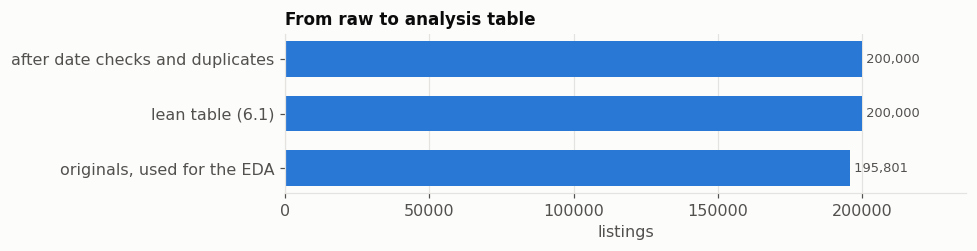

In [44]:
# 6.7c Chart: from raw to analysis table
fig, ax = plt.subplots(figsize=(9, 2.4))
bar_h(ax, pd.Series({"lean table (6.1)": start_rows, "after date checks and duplicates": len(jobs),
                     "originals, used for the EDA": len(jo)}), "From raw to analysis table", "listings")
finish()

**What the data shows**
- **Cleaning removed almost nothing:** no rows were dropped, and 4,199 reposts were set aside, leaving **195,801 original listings** for the EDA.
- **42,399 listings (21.7%) are still open at the snapshot.** That's the pool a prioritized list would rank today.
- **The main fixes were to fields, not rows:** placeholder `posted` dates, salary units, and `contract_types` labels.

## 7. Prioritization EDA

Three questions, in order. Q1 surveys every candidate prioritization factor, Q2 checks what time information the data supports, and Q3 picks the segment to go in depth on. All use the cleaned originals (`jo`); repost rates use the full cleaned table (`jobs`). Output is aggregates only.

### 7.0 Helpers

In [45]:
# 7.0a Shared constants and the largest occupation groups
COMPANY = "company_id"
TOP = 15
TOP_GROUPS = 10
top_groups = jo.occupation_group[jo.occupation_group != "(missing)"].value_counts().index[:TOP_GROUPS]
WEEKS = max((jo.first_seen.max() - jo.first_seen.min()).days / 7, 1)  # weeks covered by the sample

In [46]:
# 7.0b Small helpers
def as_list(v):
    """Nested list fields come back as lists or numpy arrays; normalize to a list."""
    if isinstance(v, (list, tuple, np.ndarray)):
        return list(v)
    return [] if v is None or (isinstance(v, float) and np.isnan(v)) else [v]

def pct(x):
    return f"{100 * x:.1f}%"

In [47]:
# 7.0c Kaplan–Meier survival helpers
def km_curve(days, finished):
    """Kaplan–Meier curve: share of postings still open after t days, indexed by t.
    Live postings count as censored, so the open ones don't bias the window short."""
    d = pd.DataFrame({"t": days, "e": finished}).dropna()
    by_t = d.groupby("t")["e"].agg(["size", "sum"])
    at_risk = len(d) - by_t["size"].cumsum().shift(fill_value=0)
    return (1 - by_t["sum"] / at_risk).cumprod()

def surv_at(curve, x):
    return curve[curve.index <= x].iloc[-1] if (curve.index <= x).any() else 1.0

def km_survival(days, finished, at):
    curve = km_curve(days, finished)
    return [surv_at(curve, x) for x in at]

def km_median(days, finished):
    """Days until half of postings have closed; NaN if more than half are still open."""
    curve = km_curve(days, finished)
    return curve[curve <= 0.5].index.min()

### 7.1 Q1: Which factors should drive prioritization?

Every candidate factor, measured for the largest occupation groups. A factor is only useful for ranking if it **varies**: if every listing has the same chance of still being open, that factor can't separate a good listing from a weak one. So for each factor, Q1a shows the overall value, the range across occupation groups, and the spread (max ÷ min).

| Measure | Prioritization factor | What it tells an applicant | Caveat |
|---|---|---|---|
| Median days open | Still open / apply-by | How long the window to apply is | Disappearing ≠ filled |
| Closed within 7 days | Still open / apply-by | How urgent applying is | Same |
| New listings per week | Freshness, source | How often new listings arrive, so how often to check | Depends on crawl frequency |
| Still open at snapshot | Still open | How many listings are rankable right now | One day only |
| Repost rate | Competition | Jobs that didn't fill may mean less competition | Could also mean a bad job |
| Salary disclosed, median salary | Pay | Whether a listing is worth an application | Pay is listed for under half of listings |
| Urgency wording, mentions remote | Employer intent | Whether the employer is in a hurry or flexible | Simple keyword flags for now |
| From a hiring platform | Source | Where listings are hosted | Inferred from the url domain |
| Top 10 companies' share | Competition, source | Whether a few employers dominate, so a short watch list covers most listings | Sample may over-represent some companies |

Q1b–Q1f look at the most promising factors in more detail.

In [48]:
# 7.1 Q1a: define the candidate prioritization factors
def targets(g, g_all):
    """Candidate prioritization factors for one group. g = originals, g_all = originals + reposts."""
    curve = km_curve(g.days_open, ~g.live)
    return pd.Series({
        "median days open (KM)": curve[curve <= 0.5].index.min(),
        "closed within 7 days": 1 - surv_at(curve, 7),
        "new postings per week": len(g) / WEEKS,
        "still open at snapshot": g.live.sum(),
        "repost rate": g_all.is_repost.mean(),
        "salary disclosed": g.salary_annual_usd.notna().mean(),
        "median annual salary (USD)": g.salary_annual_usd.median(),
        "urgency wording": g.urgency.mean(),
        "mentions remote": g.mentions_remote.mean(),
        "from a hiring platform": (g.source_type == "hiring platform").mean(),
        "top 10 companies' share": g[COMPANY].value_counts().head(10).sum() / len(g),
    })

In [49]:
# Q1a: compute the factors overall and per occupation group
by_group = pd.DataFrame({f: targets(jo[jo.occupation_group == f], jobs[jobs.occupation_group == f]) for f in top_groups}).T
overview = pd.DataFrame({
    "overall": targets(jo, jobs),
    "group min": by_group.min(),
    "group median": by_group.median(),
    "group max": by_group.max(),
})
overview["spread (max / min)"] = overview["group max"] / overview["group min"].replace(0, np.nan)
show("Q1a. Candidate prioritization factors: overall, and the range across the largest occupation groups", overview.round(2))
show("Q1a. Candidate prioritization factors by occupation group", by_group.round(2))


Q1a. Candidate prioritization factors: overall, and the range across the largest occupation groups


,overall,group min,group median,group max,spread (max / min)
median days open (KM),22.12,15.72,22.12,26.13,1.66
closed within 7 days,0.28,0.22,0.28,0.34,1.55
new postings per week,7489.66,311.86,499.03,975.18,3.13
still open at snapshot,42399.00,1768.00,2600.50,5007.00,2.83
repost rate,0.02,0.01,0.01,0.09,10.28
salary disclosed,0.43,0.40,0.45,0.49,1.21
median annual salary (USD),61171.42,38402.00,51820.60,137500.00,3.58
urgency wording,0.09,0.06,0.10,0.14,2.38
mentions remote,0.11,0.02,0.09,0.25,12.69
from a hiring platform,0.30,0.24,0.31,0.35,1.47



Q1a. Candidate prioritization factors by occupation group


,median days open (KM),closed within 7 days,new postings per week,still open at snapshot,repost rate,salary disclosed,median annual salary (USD),urgency wording,mentions remote,from a hiring platform,top 10 companies' share
Healthcare Practitioners and Technical,21.31,0.31,975.18,5007.0,0.01,0.42,93745.6,0.14,0.08,0.24,0.07
Management,24.13,0.25,842.41,4842.0,0.02,0.44,100000.0,0.07,0.15,0.31,0.04
Sales and Related,23.29,0.25,722.99,4246.0,0.03,0.49,44792.8,0.09,0.12,0.35,0.06
Computer and Mathematical,19.79,0.34,600.09,3605.0,0.01,0.40,137500.0,0.06,0.25,0.24,0.07
Office and Administrative Support,19.00,0.29,560.11,2738.0,0.01,0.41,45780.8,0.09,0.10,0.35,0.05
Business and Financial Operations,22.12,0.29,437.94,2463.0,0.01,0.41,84980.0,0.06,0.19,0.30,0.06
Transportation and Material Moving,15.72,0.34,411.39,2010.0,0.05,0.47,44720.0,0.13,0.04,0.31,0.07
"Installation, Maintenance, and Repair",26.13,0.24,321.50,1989.0,0.01,0.45,57200.0,0.11,0.05,0.35,0.08
Healthcare Support,22.13,0.27,317.49,1768.0,0.01,0.45,46441.2,0.12,0.05,0.31,0.06
Food Preparation and Serving Related,25.62,0.22,311.86,1997.0,0.09,0.47,38402.0,0.11,0.02,0.33,0.10


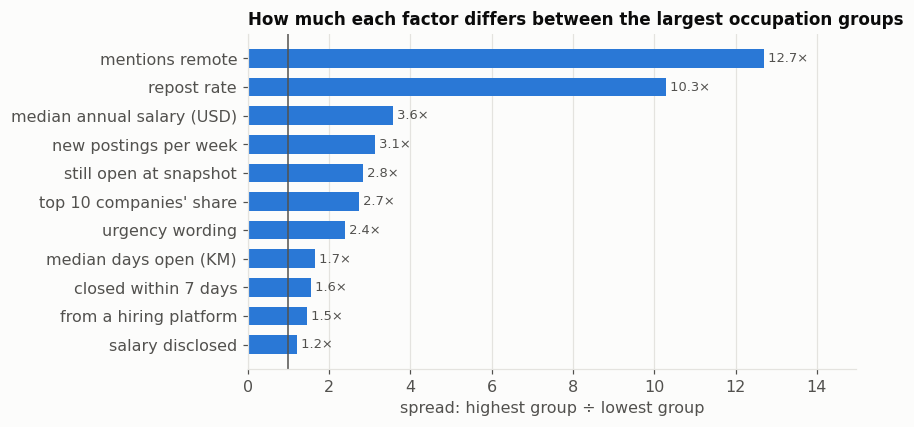

In [50]:
# Q1a chart: how much each factor differs between occupation groups
fig, ax = plt.subplots(figsize=(8, 4))
bar_h(ax, overview["spread (max / min)"], "How much each factor differs between the largest occupation groups",
      "spread: highest group ÷ lowest group", "{:.1f}×")
ax.axvline(1, color=INK_2, lw=1)
finish()

**What the data shows**
- **Biggest differences between occupation groups:**
  - **Mentions remote:** 12.7×, from 2% (food preparation) to 25% (computer and mathematical).
  - **Repost rate:** 10.3×, from 0.9% (healthcare practitioners) to 9.0% (food preparation).
  - **Pay:** 3.6×, from a $38k median (food preparation) to $137.5k (computer and mathematical).
- **Moderate differences:**
  - **New listings per week:** 3.1×.
  - **Urgency wording:** 2.4×.
  - **Days open:** 1.7×, from a median of 15.7 days (transportation) to 26.1 (installation and repair).
- **Barely differs:** salary disclosure (40–49% in every occupation group) and hiring-platform share. These don't separate occupation groups, but Q1c and Q1f show they still separate *listings* within an occupation group.
- **For prioritization,** remote, competition (reposts) and pay change a lot by field, so a model must be tuned per segment.

#### Q1b. Still open / apply-by

The share of listings still open N days after first being seen, using Kaplan–Meier survival curves. These treat still-open listings as unfinished rather than ignoring them, which would make windows look shorter than they are. This is the basis for an **apply-by estimate** on each listing.

In [51]:
# 7.1 Q1b: application window by occupation group
DAYS = [3, 7, 14, 30, 60]
window = {f: km_survival(g.days_open, ~g.live, DAYS) for f, g in jo[jo.occupation_group.isin(top_groups)].groupby("occupation_group")}
window["(all postings)"] = km_survival(jo.days_open, ~jo.live, DAYS)
show("Q1b. Share of listings still open N days after first seen (Kaplan–Meier)",
     pd.DataFrame(window, index=[f"open after {d}d" for d in DAYS]).T.loc[list(top_groups) + ["(all postings)"]].round(2))


Q1b. Share of listings still open N days after first seen (Kaplan–Meier)


,open after 3d,open after 7d,open after 14d,open after 30d,open after 60d
Healthcare Practitioners and Technical,0.84,0.69,0.60,0.40,0.20
Management,0.86,0.75,0.66,0.44,0.23
Sales and Related,0.86,0.75,0.66,0.43,0.23
Computer and Mathematical,0.78,0.66,0.58,0.41,0.24
Office and Administrative Support,0.84,0.71,0.61,0.37,0.17
Business and Financial Operations,0.82,0.71,0.62,0.42,0.23
Transportation and Material Moving,0.79,0.66,0.56,0.34,0.18
"Installation, Maintenance, and Repair",0.87,0.76,0.67,0.46,0.25
Healthcare Support,0.86,0.73,0.63,0.41,0.21
Food Preparation and Serving Related,0.88,0.78,0.69,0.44,0.24


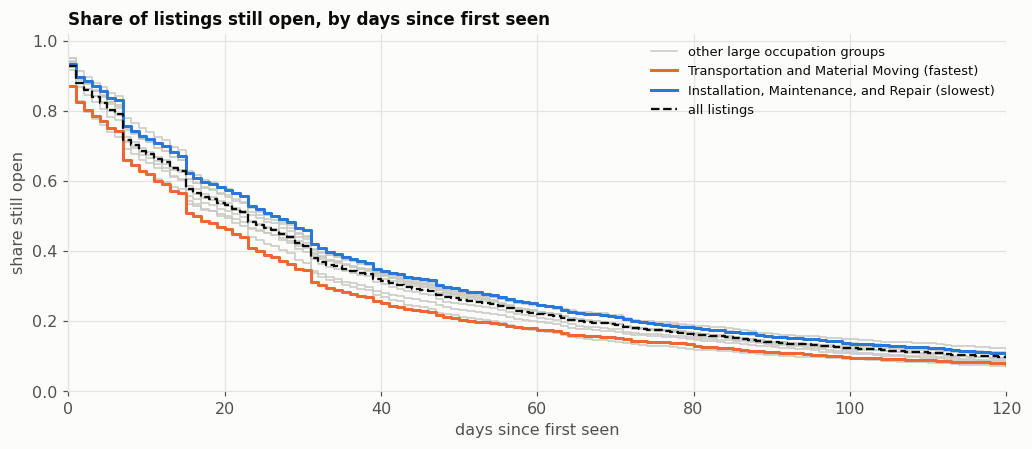

In [52]:
# Q1b chart: survival curves for the fastest and slowest occupation groups
grid = np.arange(0, 121)
def on_grid(curve):
    return curve.reindex(curve.index.union(grid)).ffill().reindex(grid).fillna(1.0)

medians = {f: km_median(g.days_open, ~g.live) for f, g in jo[jo.occupation_group.isin(top_groups)].groupby("occupation_group")}
fast, slow = min(medians, key=medians.get), max(medians, key=medians.get)
fig, ax = plt.subplots(figsize=(9.5, 4.2))
for f, g in jo[jo.occupation_group.isin(top_groups)].groupby("occupation_group"):
    if f not in (fast, slow):
        ax.step(grid, on_grid(km_curve(g.days_open, ~g.live)), where="post", color=MUTED, lw=1)
ax.plot([], [], color=MUTED, lw=1, label="other large occupation groups")
for f, color, tag in ((fast, ORANGE, "fastest"), (slow, BLUE, "slowest")):
    g = jo[jo.occupation_group == f]
    ax.step(grid, on_grid(km_curve(g.days_open, ~g.live)), where="post", color=color, label=f"{f} ({tag})")
ax.step(grid, on_grid(km_curve(jo.days_open, ~jo.live)), where="post", color=INK, lw=1.5, ls="--", label="all listings")
ax.set(title="Share of listings still open, by days since first seen", xlabel="days since first seen",
       ylabel="share still open", xlim=(0, 120), ylim=(0, 1.02))
ax.legend(fontsize=8.5)
finish()

**What the data shows**
- **The application window is short.** Across all listings, 28% are gone within 7 days, 59% within 30 days, and 78% within 60 days. The median listing is gone after about 22 days.
- **It differs by field.** Transportation and computer and mathematical lose 34% of listings in the first week; food preparation loses 22%.
- **For prioritization,** "still open / apply-by" is a strong factor. A week's delay costs between a fifth and a third of the options, depending on the field, so apply-by estimates must be specific to the occupation group.

#### Q1c. Source

Which hiring platforms, job boards or company sites host the listings, and whether arrival rate and application window differ by source. If windows differ by source, a listing's source should change its priority, and how often to check each source.

The data comes from PredictLeads' crawl of company sites and platforms, so job boards will be under-represented. This shows where listings originate, not every place they're re-posted.

In [53]:
# 7.1 Q1c: sources: share of postings, arrival rate, window
show("Q1c. Source type", pd.DataFrame({"listings": jo.source_type.value_counts(),
                                       "share": jo.source_type.value_counts(normalize=True).round(3)}))
src = jo.assign(source=jo.platform.fillna(jo.source_type))
by_src = src.groupby("source").apply(include_groups=False, func=lambda g: pd.Series({
    "postings": len(g),
    "share": len(g) / len(jo),
    "new per week": len(g) / WEEKS,
    "median days open (KM)": km_median(g.days_open, ~g.live),
    "open after 7d": km_survival(g.days_open, ~g.live, [7])[0],
}))
show("Q1c. Platforms and other sources: volume, arrival rate, window", by_src.sort_values("postings", ascending=False).head(TOP).round(2))


Q1c. Source type


,listings,share
source_type,,
company site / other,119161,0.609
hiring platform,57789,0.295
job board,18851,0.096



Q1c. Platforms and other sources: volume, arrival rate, window


,postings,share,new per week,median days open (KM),open after 7d
source,,,,,
company site / other,119161.0,0.61,4558.07,19.03,0.66
Workday,21328.0,0.11,815.83,28.18,0.82
LinkedIn,18268.0,0.09,698.78,17.00,0.75
UKG,4818.0,0.02,184.30,32.16,0.87
ADP,4584.0,0.02,175.34,24.23,0.81
Paylocity,4298.0,0.02,164.40,33.17,0.86
Oracle,3841.0,0.02,146.92,22.60,0.77
Dayforce,3733.0,0.02,142.79,30.16,0.85
iCIMS,3226.0,0.02,123.40,26.23,0.83


In [54]:
# Q1c: source mix within the largest occupation groups
mix = pd.crosstab(src.occupation_group, src.source, normalize="index").loc[top_groups]
show("Q1c. Source mix within the largest occupation groups (% of each occupation group's listings)",
     (100 * mix[mix.sum().sort_values(ascending=False).index[:8]]).round(1))


Q1c. Source mix within the largest occupation groups (% of each occupation group's listings)


source,company site / other,Workday,LinkedIn,UKG,ADP,Paylocity,Dayforce,Oracle
occupation_group,,,,,,,,
Healthcare Practitioners and Technical,65.5,11.0,10.2,2.0,1.1,1.5,1.0,1.3
Management,58.5,11.2,10.2,2.2,2.9,2.1,1.8,1.6
Sales and Related,55.0,13.5,9.3,2.6,2.3,2.1,3.2,3.6
Computer and Mathematical,68.5,9.1,6.9,0.9,1.1,0.9,0.8,2.2
Office and Administrative Support,55.0,13.9,9.6,3.4,3.5,3.0,2.1,2.0
Business and Financial Operations,59.7,12.6,9.8,1.9,2.4,1.8,1.3,1.7
Transportation and Material Moving,58.6,11.0,10.3,3.3,2.8,2.7,2.9,3.1
"Installation, Maintenance, and Repair",55.5,12.0,8.6,3.3,3.1,3.1,3.4,1.2
Healthcare Support,59.8,11.1,9.2,2.5,1.5,3.0,1.8,1.7


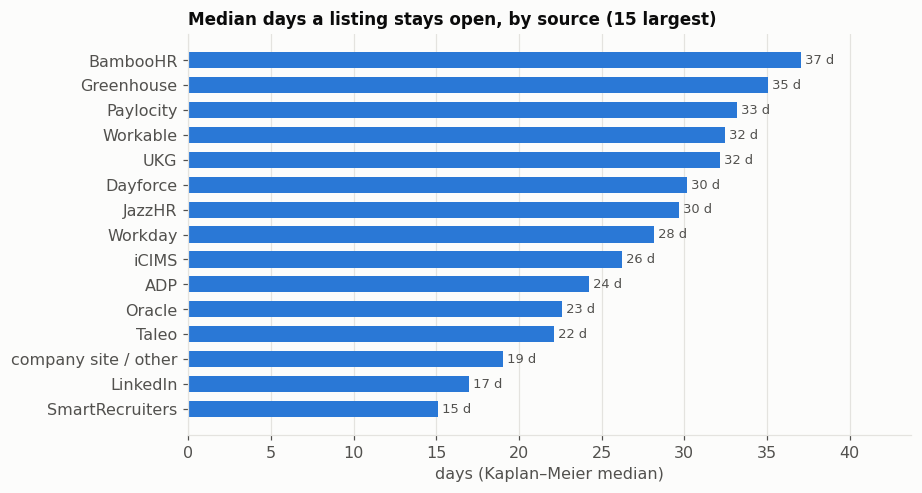

In [55]:
# Q1c chart: median days open by source
fig, ax = plt.subplots(figsize=(8.5, 4.6))
top_src = by_src.sort_values("postings", ascending=False).head(TOP)
bar_h(ax, top_src["median days open (KM)"], "Median days a listing stays open, by source (15 largest)", "days (Kaplan–Meier median)", "{:.0f} d")
finish()

**What the data shows**
- **Source is one of the strongest signals.** Median days open ranges from **15 (SmartRecruiters), 17 (LinkedIn) and 19 (company sites)** to **33–37 (Paylocity, Greenhouse, BambooHR)**.
- **Listings on company sites close fastest:** only 66% are still open after a week. On most hiring platforms it's 82–89%.
- **The source mix is similar across occupation groups:** company sites host 55–69% of every occupation group's listings. Source separates *listings*, not fields.
- **Caveat:** platforms may expose closures differently to the crawler, and platform choice is linked to employer size (Q1d). The prioritization model should test source alongside company volume, not alone.

#### Q1d. Competition: company hiring volume

If a few companies post most of an occupation group's listings, they shape the ranking, and an applicant can watch them directly. Companies that post many listings may be hiring at volume, which could mean less competition per opening. Here we check concentration, and whether listings from high-volume companies close faster or slower.

In [56]:
# 7.1 Q1d: company concentration by occupation group
def concentration(g):
    per_co = g[COMPANY].value_counts()
    return pd.Series({
        "companies": per_co.size,
        "postings per company (median)": per_co.median(),
        "top 1% of companies' share": per_co.head(max(1, per_co.size // 100)).sum() / len(g),
        "top 10% of companies' share": per_co.head(max(1, per_co.size // 10)).sum() / len(g),
        "companies with 5+ postings": (per_co >= 5).sum(),
    })
show("Q1d. Company concentration by occupation group",
     jo[jo.occupation_group.isin(top_groups)].groupby("occupation_group").apply(concentration, include_groups=False).loc[top_groups].round(2))


Q1d. Company concentration by occupation group


,companies,postings per company (median),top 1% of companies' share,top 10% of companies' share,companies with 5+ postings
occupation_group,,,,,
Healthcare Practitioners and Technical,6006.0,1.0,0.21,0.60,1082.0
Management,12093.0,1.0,0.13,0.40,685.0
Sales and Related,7364.0,1.0,0.21,0.54,691.0
Computer and Mathematical,7152.0,1.0,0.20,0.49,507.0
Office and Administrative Support,8431.0,1.0,0.14,0.39,441.0
Business and Financial Operations,6668.0,1.0,0.14,0.39,323.0
Transportation and Material Moving,4161.0,1.0,0.19,0.53,405.0
"Installation, Maintenance, and Repair",4445.0,1.0,0.16,0.42,254.0
Healthcare Support,3346.0,1.0,0.14,0.48,357.0


In [57]:
# Q1d: do high-volume companies' listings close faster or slower?
co_postings = jo[COMPANY].value_counts()
def size_band(company_ids):
    return pd.cut(company_ids.map(co_postings).fillna(1), [0, 1, 4, 19, np.inf],
                  labels=["1 posting", "2-4", "5-19", "20+"])
by_band = jo.groupby(size_band(jo[COMPANY]), observed=True).apply(lambda g: pd.Series({
    "share of postings": len(g) / len(jo),
    "median days open (KM)": km_median(g.days_open, ~g.live),
}))
by_band["repost rate"] = jobs.groupby(size_band(jobs[COMPANY]), observed=True).is_repost.mean()
show("Q1d. Do high-volume companies' listings close faster or slower?", by_band.round(2))


Q1d. Do high-volume companies' listings close faster or slower?


,share of postings,median days open (KM),repost rate
company_id,,,
1 posting,0.16,32.16,0.01
2-4,0.17,29.51,0.01
5-19,0.25,24.14,0.02
20+,0.42,14.08,0.03


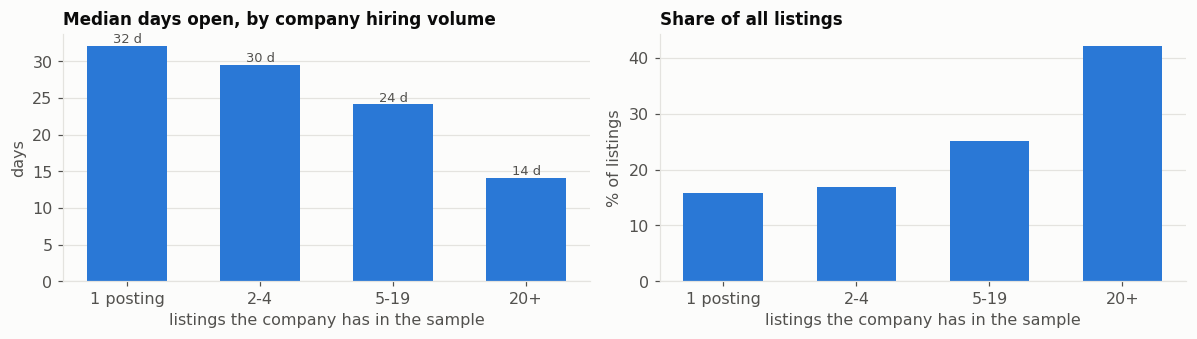

In [58]:
# Q1d charts: days open and share of listings, by company hiring volume
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.2))
order = ["1 posting", "2-4", "5-19", "20+"]
by_band = by_band.reindex(order)
ax1.bar(order, by_band.loc[order, "median days open (KM)"], color=BLUE, width=0.6)
for x, v in enumerate(by_band.loc[order, "median days open (KM)"]):
    ax1.text(x, v, f"{v:.0f} d", ha="center", va="bottom", color=INK_2, fontsize=8.5)
ax1.set(title="Median days open, by company hiring volume", xlabel="listings the company has in the sample", ylabel="days")
ax1.grid(axis="x", visible=False)
ax2.bar(order, 100 * by_band.loc[order, "share of postings"], color=BLUE, width=0.6)
ax2.set(title="Share of all listings", xlabel="listings the company has in the sample", ylabel="% of listings")
ax2.grid(axis="x", visible=False)
finish()

**What the data shows**
- **This is the strongest single signal in the EDA.** Listings from companies with 20 or more openings stay open a median of **14 days**; single-listing companies' stay open **32 days**, more than twice as long.
- **High-volume employers dominate:** they post 42% of all listings. In every occupation group the top 10% of companies post 39–60% of listings, and healthcare practitioners is the most concentrated at 60%.
- **For prioritization:** a listing from a high-volume employer needs fast action. Watching about 300–1,100 high-volume companies per occupation group (those with 5+ listings) would cover a large share of openings.
- **Reposts are more common at high-volume companies** (3% vs. 1%), which fits frequent, rolling hiring.

#### Q1e. Competition: reposts

A repost is the same job (company, title and description) listed again under a new id. It suggests the first listing didn't fill, which could mean less competition, or a hard-to-fill or unattractive role. Here we check how common reposts are and how long the gap is between original and repost.

In [59]:
# 7.1 Q1e: repost rates and gaps
show("Q1e. Repost rate by occupation group", jobs[jobs.occupation_group.isin(top_groups)].groupby("occupation_group").agg(
    listings=("is_repost", "size"), reposts=("is_repost", "sum"), repost_rate=("is_repost", "mean")
).loc[top_groups].round(3))


Q1e. Repost rate by occupation group


,listings,reposts,repost_rate
occupation_group,,,
Healthcare Practitioners and Technical,25719,225,0.009
Management,22429,406,0.018
Sales and Related,19510,609,0.031
Computer and Mathematical,15844,156,0.010
Office and Administrative Support,14818,175,0.012
Business and Financial Operations,11595,146,0.013
Transportation and Material Moving,11313,558,0.049
"Installation, Maintenance, and Repair",8509,104,0.012
Healthcare Support,8384,84,0.010


In [60]:
# Q1e: days from the original listing to each repost
key = ["company_id", "title_norm", "desc_hash"]
first = jobs[~jobs.is_repost & jobs[key].notna().all(axis=1)].groupby(key).first_seen.min()
reposts = jobs[jobs.is_repost].join(first.rename("original_seen"), on=key)
gap = (reposts.first_seen - reposts.original_seen).dt.total_seconds() / 86400
show("Q1e. Days from the original to each repost",
     gap.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(1).to_frame("days"))


Q1e. Days from the original to each repost


,days
count,4199.0
mean,28.4
std,33.0
min,0.0
10%,1.0
25%,6.0
50%,16.0
75%,37.4
90%,79.0
max,183.3


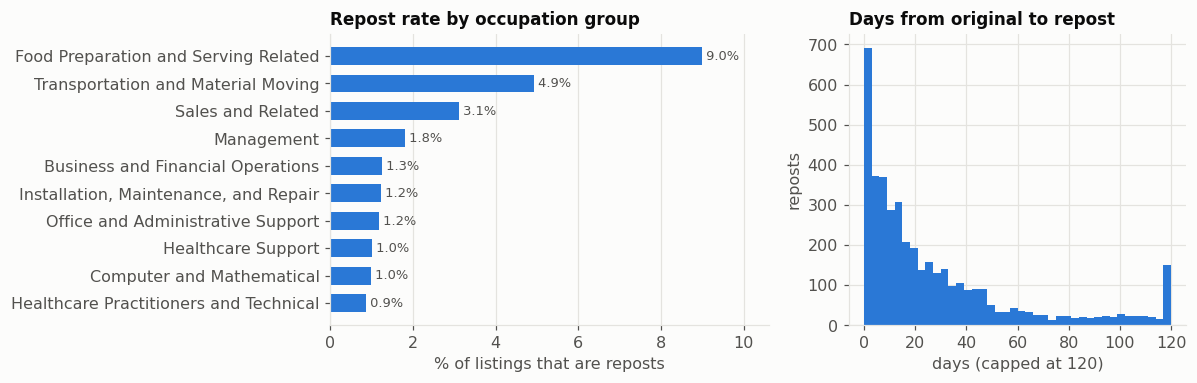

In [61]:
# Q1e charts: repost rate and repost gap
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.3, 1]})
rates = jobs[jobs.occupation_group.isin(top_groups)].groupby("occupation_group").is_repost.mean()
bar_h(ax1, 100 * rates, "Repost rate by occupation group", "% of listings that are reposts", "{:.1f}%")
ax2.hist(gap.clip(upper=120), bins=40, color=BLUE)
ax2.set(title="Days from original to repost", xlabel="days (capped at 120)", ylabel="reposts")
finish()

**What the data shows**
- **Reposting is concentrated in hourly, high-turnover fields:** food preparation (9.0%), transportation (4.9%) and sales (3.1%). Most other occupation groups sit near 1%.
- **Reposts come back quickly:** a median of 16 days after the original, and a quarter within 6 days.
- **For prioritization:** a repost is a useful competition signal in those three fields. The employer didn't fill the role the first time. Elsewhere it's too rare to matter.

#### Q1f. Employer intent: text signals (the NLP link)

A first look at whether simple text features go with listings staying open longer or shorter. Each row compares listings with and without the feature. These are keyword flags, not models. If any of them show a gap, richer text features (TF-IDF, topics, embeddings) are worth modeling as prioritization inputs.

In [62]:
# 7.1 Q1f: do text features relate to how long postings stay open?
flags = {
    "salary disclosed": jo.salary_annual_usd.notna(),
    "mentions remote": jo.mentions_remote,
    "urgency wording": jo.urgency,
    "long description (top 25%)": jo.desc_words > jo.desc_words.quantile(0.75),
    "on a hiring platform": jo.source_type == "hiring platform",
}
rows = {}
for name, mask in flags.items():
    with_f = km_survival(jo.days_open[mask], ~jo.live[mask], [7, 30])
    without = km_survival(jo.days_open[~mask], ~jo.live[~mask], [7, 30])
    rows[name] = {"share of postings": mask.mean(), "open 7d (with)": with_f[0], "open 7d (without)": without[0],
                  "open 30d (with)": with_f[1], "open 30d (without)": without[1]}
show("Q1f. Text features vs. application window (all occupation groups)", pd.DataFrame(rows).T.round(2))


Q1f. Text features vs. application window (all occupation groups)


,share of postings,open 7d (with),open 7d (without),open 30d (with),open 30d (without)
salary disclosed,0.43,0.78,0.67,0.46,0.38
mentions remote,0.11,0.76,0.71,0.46,0.41
urgency wording,0.09,0.79,0.71,0.44,0.41
long description (top 25%),0.25,0.81,0.69,0.46,0.40
on a hiring platform,0.30,0.83,0.67,0.51,0.38


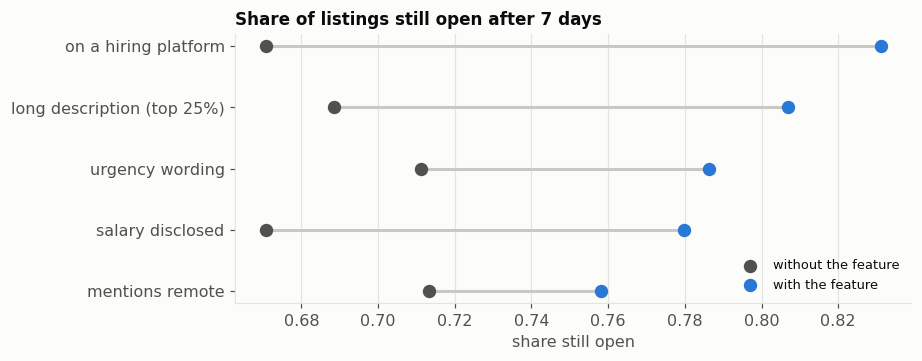

In [63]:
# Q1f chart: share still open after 7 days, with vs. without each feature
feat = pd.DataFrame(rows).T.sort_values("open 7d (with)")
fig, ax = plt.subplots(figsize=(8.5, 3.4))
y = np.arange(len(feat))
ax.hlines(y, feat["open 7d (without)"], feat["open 7d (with)"], color=MUTED, lw=2)
ax.scatter(feat["open 7d (without)"], y, color=INK_2, s=60, zorder=3, label="without the feature")
ax.scatter(feat["open 7d (with)"], y, color=BLUE, s=60, zorder=3, label="with the feature")
ax.set_yticks(y, feat.index)
ax.set(title="Share of listings still open after 7 days", xlabel="share still open")
ax.grid(axis="y", visible=False)
ax.legend(fontsize=8.5, loc="lower right")
finish()

**What the data shows**
- **Every text and listing feature goes with listings staying open longer:**
  - **On a hiring platform:** 83% still open after a week, vs. 67% without.
  - **Long description:** 81% vs. 69%.
  - **Salary disclosed:** 78% vs. 67%.
  - **Urgency wording:** 79% vs. 71%. This is counter-intuitive, and may mark hard-to-fill roles.
  - **Mentions remote:** 76% vs. 71%.
- **The text carries timing signal,** so NLP features are worth modeling.
- **Caveat:** these comparisons are one feature at a time, and the features overlap with each other and with company size and source. A multivariate model (Cox regression) has to separate them before any feature is used for ranking.

### 7.2 Q2: What time information can prioritization rely on?

Several factors and the advice that comes with the ranking depend on time:

| Time scale | Use in prioritization | Needs |
|---|---|---|
| Days since a listing appeared | Apply-by estimates and freshness | Closed listings with both dates (usually plentiful) |
| Week / day of week | How often to check for new high-priority listings | Dates that reflect employers, not the crawler |
| Season / month | When to search: busy vs. quiet months for the segment | About two years of history |

Checks:
- **History depth:** how far back `first_seen` goes, and whether the snapshot keeps listings that have already closed.
- **Sort order:** if the file is sorted by date or company, our first-200,000 sample is biased.
- **Crawler or employer?** Where both dates exist, compare `posted` with `first_seen`. If their weekday patterns differ, `first_seen` reflects the crawler's schedule.

In [64]:
# 7.2 Q2a: how much history does the snapshot hold?
show("Q2a. How much history does the snapshot hold?", pd.DataFrame({"value": {
    "first_seen from": jo.first_seen.min().date(),
    "first_seen to": jo.first_seen.max().date(),
    "distinct months": jo.month.nunique(),
    "complete years": jo.month.nunique() // 12,
    "share already closed by the snapshot (high = keeps history)": round((~jo.live).mean(), 3),
}}))
show("Q2a. Listings by first_seen year", jo.first_seen.dt.year.value_counts().sort_index()
     .rename_axis("year").to_frame("listings"))
show("Q2a. Listings by first_seen month (last 24)", jo.month.value_counts().sort_index().tail(24)
     .rename_axis("month").to_frame("listings"))


Q2a. How much history does the snapshot hold?


,value
first_seen from,2026-03-30
first_seen to,2026-09-30
distinct months,7
complete years,0
share already closed by the snapshot (high = keeps history),0.783



Q2a. Listings by first_seen year


,listings
year,
2026,195801



Q2a. Listings by first_seen month (last 24)


,listings
month,
2026-03,2658
2026-04,36900
2026-05,36388
2026-06,27015
2026-07,29234
2026-08,31208
2026-09,32398


In [65]:
# Q2b: is the file sorted by date or company?
in_file_order = jobs.sort_index()  # index = original file order
order_corr = pd.Series(np.arange(len(in_file_order))).corr(
    in_file_order.first_seen.rank().reset_index(drop=True), method="spearman")
same_company = in_file_order[COMPANY] == in_file_order[COMPANY].shift()
show("Q2b. Is the file sorted?", pd.DataFrame({
    "value": {"rank correlation of file order with first_seen": round(order_corr, 2),
              "rows whose company matches the previous row": round(same_company.mean(), 3)},
    "how to read": {"rank correlation of file order with first_seen": "near 0 = not sorted by date",
                    "rows whose company matches the previous row": "high = grouped by company"},
}))


Q2b. Is the file sorted?


,value,how to read
rank correlation of file order with first_seen,0.0,near 0 = not sorted by date
rows whose company matches the previous row,0.0,high = grouped by company


In [66]:
# Q2c: employer or crawler? posted vs. first_seen
both = jo.posted.notna()
lag = (jo.first_seen - jo.posted)[both].dt.total_seconds() / 86400
show(f"Q2c. Days from posted to first_seen (listings with posted: {pct(both.mean())})",
     lag.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9]).round(1).to_frame("days"))
days = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday = pd.DataFrame({
    "posted (UTC)": jo.posted[both].dt.day_name().value_counts(normalize=True),
    # posted timestamps sit at 22:00/23:00 UTC = midnight Central European time, so read them as CET dates
    "posted (CET date)": jo.posted[both].dt.tz_convert("Europe/Berlin").dt.day_name().value_counts(normalize=True),
    "first_seen, same listings": jo.first_seen[both].dt.day_name().value_counts(normalize=True),
    "first_seen, all listings": jo.first_seen.dt.day_name().value_counts(normalize=True),
}).reindex(days)
show("Q2c. % of listings by weekday (if the columns disagree, first_seen reflects the crawler)",
     (100 * weekday).round(1))


Q2c. Days from posted to first_seen (listings with posted: 40.8%)


,days
count,79794.0
mean,6.3
std,54.7
min,-1.0
10%,0.3
25%,0.9
50%,1.5
75%,3.7
90%,8.1
max,4531.9



Q2c. % of listings by weekday (if the columns disagree, first_seen reflects the crawler)


,posted (UTC),posted (CET date),"first_seen, same listings","first_seen, all listings"
Monday,17.8,15.0,10.6,11.3
Tuesday,18.5,18.4,18.8,17.9
Wednesday,18.4,18.7,16.7,16.8
Thursday,17.1,18.5,16.0,16.4
Friday,9.0,16.3,19.8,18.5
Saturday,6.2,8.0,10.2,10.7
Sunday,13.0,5.0,7.9,8.5


In [67]:
# Q2d: weekly arrivals
weekly = jo.first_seen.dt.tz_localize(None).dt.to_period("W").value_counts().sort_index()
show("Q2d. Weekly arrivals: enough weeks for a check cadence?", pd.DataFrame({"value": {
    "weeks with listings": weekly.size,
    "median new listings per week": weekly.median(),
    "complete years of monthly data (seasonal decomposition needs 2+)": jo.month.nunique() // 12,
}}))


Q2d. Weekly arrivals: enough weeks for a check cadence?


,value
weeks with listings,27.0
median new listings per week,7186.0
complete years of monthly data (seasonal decomposition needs 2+),0.0


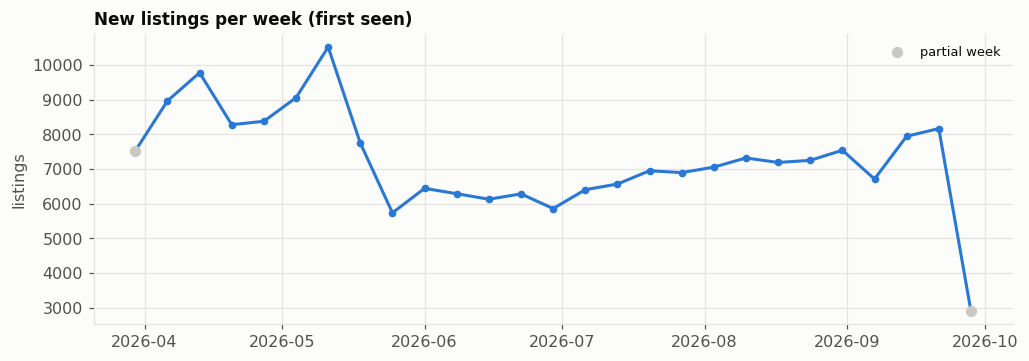

In [68]:
# Q2 chart: new listings per week
fig, ax = plt.subplots(figsize=(9.5, 3.4))
wk = weekly.copy()
partial = [wk.index[0], wk.index[-1]]  # first and last weeks are cut off by the window
ax.plot([p.start_time for p in wk.index], wk.values, color=BLUE, marker="o", ms=4)
ax.scatter([p.start_time for p in partial], wk[partial].values, color=MUTED, s=40, zorder=3, label="partial week")
ax.set(title="New listings per week (first seen)", ylabel="listings")
ax.legend(fontsize=8.5)
finish()

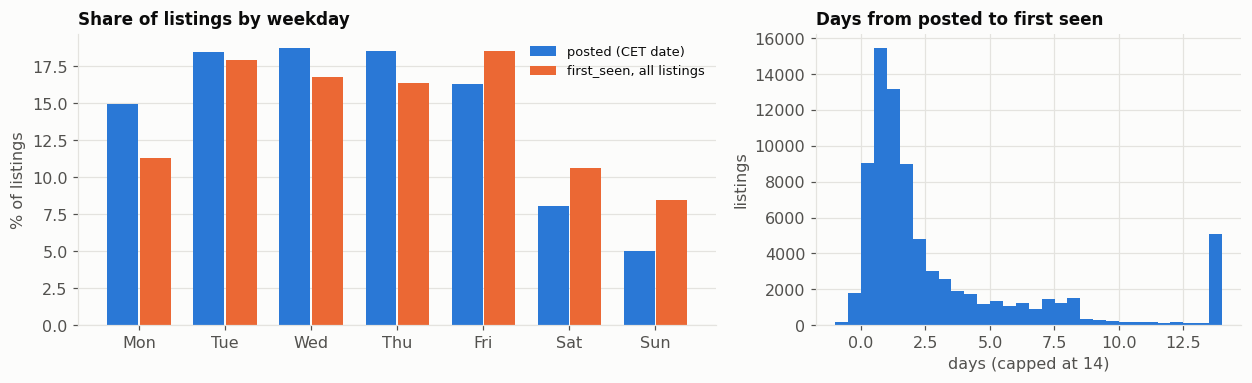

In [69]:
# Q2 charts: weekday shares and the posted-to-first-seen lag
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3.6), gridspec_kw={"width_ratios": [1.5, 1]})
x = np.arange(len(days))
for k, (col, color) in enumerate([("posted (CET date)", BLUE), ("first_seen, all listings", ORANGE)]):
    ax1.bar(x + (k - 0.5) * 0.38, 100 * weekday[col], width=0.36, color=color, label=col)
ax1.set_xticks(x, [d[:3] for d in days])
ax1.set(title="Share of listings by weekday", ylabel="% of listings")
ax1.grid(axis="x", visible=False)
ax1.legend(fontsize=8.5)
ax2.hist(lag.clip(-1, 14), bins=30, color=BLUE)
ax2.set(title="Days from posted to first seen", xlabel="days (capped at 14)", ylabel="listings")
finish()

**What the data shows**
- **There are only six months of history** (2026-03-30 to 2026-09-30, no complete year), so **seasonal advice isn't supported.** It would need older snapshots, a question already in the PredictLeads email. Weekly volume is steady at around 7,200 new listings, with a dip in June. The same ~0.42 monthly variation in every occupation group (Q3a) comes from the partial first month, not from seasonality.
- **The file isn't sorted** by date or company (both checks ≈ 0), so the first-200,000 sample shows no ordering bias.
- **`first_seen` is a good freshness clock:** the crawler finds a listing a median of 1.5 days after it's posted. 75% are found within 3.7 days, and 90% within 8 days.
- **`first_seen` weekdays follow the crawler, not employers:** they peak on Friday (18.5%) and dip on Monday (11.3%). In UTC, `posted` is uneven too (Sunday 13%, Friday 9%), but its timestamps are midnight Central European time. Read as CET dates, `posted` should show a normal working week; the chart above uses the CET reading.
- **For prioritization:**
  - **Posting age is fully supported,** for apply-by estimates and freshness.
  - **A check-cadence (day-of-week) factor must use `posted`,** which covers only 41% of listings, not `first_seen`.
  - **Seasonal context is out of reach** with this data.

### 7.3 Q3: Which segment do we go in depth on?

A good segment (occupation group × country) has:
- **Many listings and many companies,** so no single employer dominates (`top_company_share` should be low)
- **Measurable timing:** plenty of closed listings (`closed_share`) and reasonable `posted` coverage, for apply-by estimates
- **Variation in the Q1 factors,** so prioritization has something nuanced to rank on
- **Some monthly variation** (`monthly_cv`), a rough hint of seasonality. It's also affected by how the sample was drawn, so treat it as a lead, not a finding.

In [70]:
# 7.3 Q3a: occupation groups ranked by size
def group_stats(g):
    monthly = g.month.value_counts()
    return pd.Series({
        "postings": len(g),
        "companies": g[COMPANY].nunique(),
        "top_company_share": g[COMPANY].value_counts(normalize=True).iloc[0],
        "closed_share": (~g.live).mean(),
        "median_days_open_closed": g.loc[~g.live, "days_open"].median(),
        "posted_share": g.posted.notna().mean(),
        "salary_share": g.salary_annual_usd.notna().mean(),
        "months": monthly.size,
        "monthly_cv": monthly.std() / monthly.mean(),
    })

grp = jo.groupby("occupation_group").apply(group_stats, include_groups=False).sort_values("postings", ascending=False)
show("Q3a. Occupation groups ranked by size", grp.head(20).round(2))


Q3a. Occupation groups ranked by size


,postings,companies,top_company_share,closed_share,median_days_open_closed,posted_share,salary_share,months,monthly_cv
occupation_group,,,,,,,,,
Healthcare Practitioners and Technical,25494.0,6006.0,0.01,0.80,14.08,0.41,0.42,7.0,0.43
Management,22023.0,12093.0,0.01,0.78,16.05,0.43,0.44,7.0,0.42
Sales and Related,18901.0,7364.0,0.01,0.78,15.53,0.44,0.49,7.0,0.42
Computer and Mathematical,15688.0,7152.0,0.01,0.77,11.12,0.34,0.40,7.0,0.41
Office and Administrative Support,14643.0,8431.0,0.01,0.81,14.08,0.44,0.41,7.0,0.42
Business and Financial Operations,11449.0,6668.0,0.01,0.78,14.09,0.43,0.41,7.0,0.43
Transportation and Material Moving,10755.0,4161.0,0.02,0.81,12.13,0.43,0.47,7.0,0.43
"Installation, Maintenance, and Repair",8405.0,4445.0,0.02,0.76,16.15,0.40,0.45,7.0,0.42
Healthcare Support,8300.0,3346.0,0.01,0.79,14.39,0.37,0.45,7.0,0.43


In [71]:
# Q3b–Q3d: seniority mix and countries
show("Q3b. Seniority mix of the largest occupation groups",
     pd.crosstab(jo.occupation_group, jo.seniority.fillna("(missing)")).loc[grp.index[:TOP]])

show("Q3c. Countries (first listed location)",
     jo.country.fillna("(missing)").value_counts().head(TOP).rename_axis("country").to_frame("listings"))

top_countries = jo.country.value_counts().index[:6]
show("Q3d. Listings by occupation group × country (largest occupation groups and countries)",
     pd.crosstab(jo.occupation_group, jo.country).loc[grp.index[:TOP], top_countries])


Q3b. Seniority mix of the largest occupation groups


seniority,c_level,director,founder,head,junior,manager,mid_senior,not_set,partner,president,vice_president
occupation_group,,,,,,,,,,,
Healthcare Practitioners and Technical,9,291,2,111,3143,1025,20901,0,6,0,6
Management,374,4091,38,464,746,11536,4048,0,28,26,672
Sales and Related,3,50,5,17,7358,2944,8517,0,5,0,2
Computer and Mathematical,9,316,19,138,1443,1570,12114,0,6,1,72
Office and Administrative Support,0,13,0,8,6646,804,7168,0,0,0,4
Business and Financial Operations,2,224,0,53,1775,906,8357,0,19,0,113
Transportation and Material Moving,4,5,4,7,6862,571,3295,0,2,3,2
"Installation, Maintenance, and Repair",1,5,0,3,2116,695,5585,0,0,0,0
Healthcare Support,0,3,0,0,4463,44,3786,0,4,0,0



Q3c. Countries (first listed location)


,listings
country,
United States,179086
(missing),16715



Q3d. Listings by occupation group × country (largest occupation groups and countries)


country,United States
occupation_group,
Healthcare Practitioners and Technical,24375
Management,20069
Sales and Related,17838
Computer and Mathematical,13577
Office and Administrative Support,13256
Business and Financial Operations,10296
Transportation and Material Moving,10109
"Installation, Maintenance, and Repair",7639
Healthcare Support,7895


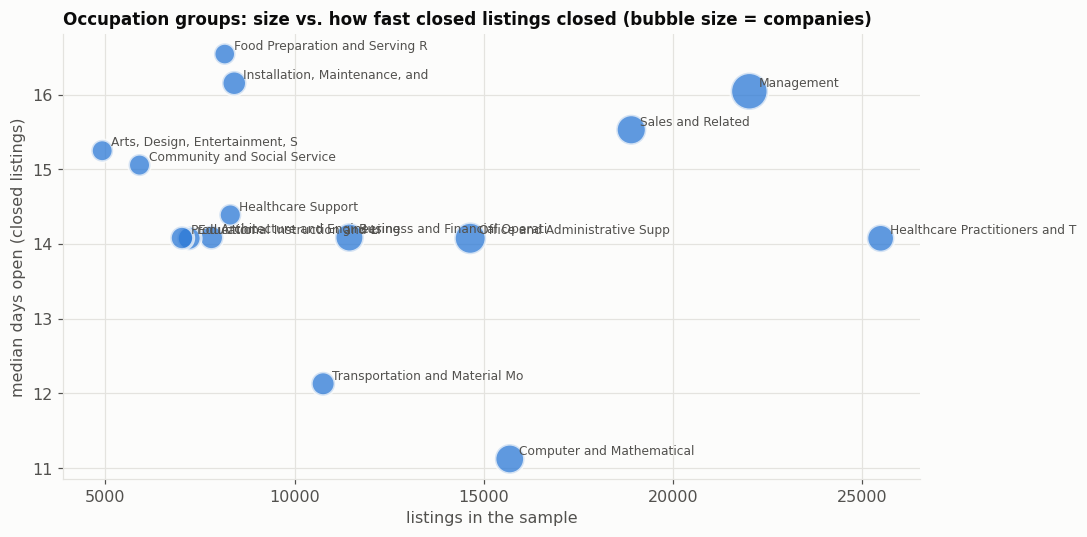

In [72]:
# Q3 chart: size vs. closing speed
top15 = grp.drop(index="(missing)", errors="ignore").head(TOP)
fig, ax = plt.subplots(figsize=(10, 5))
ax.scatter(top15.postings, top15.median_days_open_closed, s=60 + 540 * top15.companies / top15.companies.max(), color=BLUE, alpha=0.75,
           edgecolor=SURFACE, linewidth=2)
for name, r in top15.iterrows():
    ax.annotate(name[:30], (r.postings, r.median_days_open_closed), xytext=(6, 3), textcoords="offset points",
                fontsize=8, color=INK_2)
ax.set(title="Occupation groups: size vs. how fast closed listings closed (bubble size = companies)",
       xlabel="listings in the sample", ylabel="median days open (closed listings)")
finish()

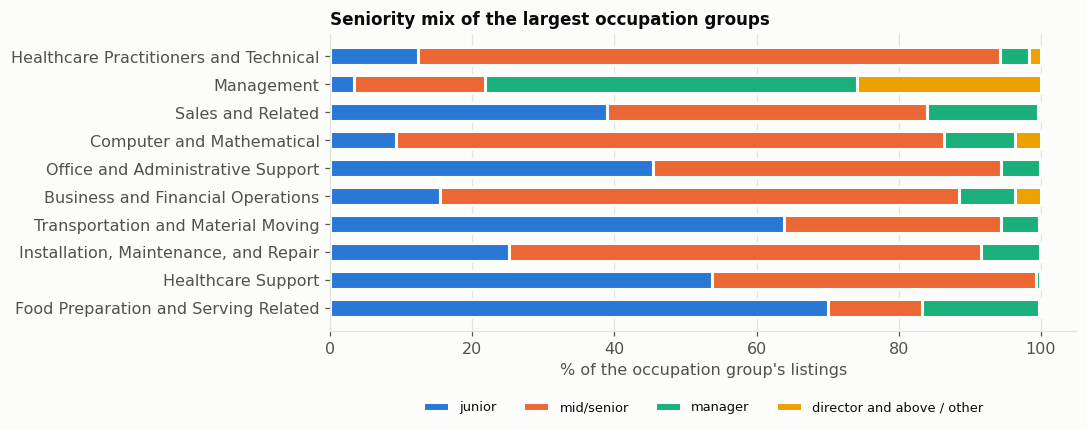

In [73]:
# Q3 chart: seniority mix
levels = {"junior": "junior", "mid_senior": "mid/senior", "manager": "manager"}
mix = pd.crosstab(jo.occupation_group, jo.seniority.map(levels).fillna("director and above / other"), normalize="index")
mix = mix.reindex(index=grp.index[:10].drop("(missing)", errors="ignore"),
                  columns=["junior", "mid/senior", "manager", "director and above / other"]).fillna(0)
fig, ax = plt.subplots(figsize=(10, 4.2))
left = np.zeros(len(mix))
for col, color in zip(mix.columns, [BLUE, ORANGE, AQUA, YELLOW]):
    ax.barh([n[:40] for n in mix.index], 100 * mix[col], left=left, color=color, height=0.65,
            edgecolor=SURFACE, linewidth=2, label=col)
    left += 100 * mix[col].values
ax.invert_yaxis()
ax.set(title="Seniority mix of the largest occupation groups", xlabel="% of the occupation group's listings")
ax.grid(axis="y", visible=False)
ax.legend(ncol=4, fontsize=8.5, loc="lower center", bbox_to_anchor=(0.5, -0.32))
finish()

**What the data shows**
- **Country isn't a choice:** every listing with a country is in the United States (91.6%; the rest are missing). The segment is an occupation group in the US.
- **Every large occupation group has enough data:** the top ten each have 8,000–25,500 listings from 3,000–12,000 companies, and no single company holds more than 2%.
- **The strongest candidates:**
  - **Computer and mathematical** (15,688 listings, 7,152 companies): the highest pay ($137.5k median), the most remote listings (25%) and among the fastest-closing (34% gone in a week). Caveat: 77% are mid/senior and only 9% junior.
  - **Healthcare practitioners** (25,494 listings): the largest occupation group, the most concentrated (the top 10% of companies post 60% of listings) and the most urgency wording (14%). High-volume employer effects should be strongest here.
  - **Sales and food preparation:** the competition (repost) signal is strongest, and they're junior-heavy, but pay is lower.
- **Recommendation for the team:** go in depth on **computer and mathematical (US)**. The factors that differ most (remote, pay, window, source) all vary within it, and team members' own résumés fit it, which helps the later fit work. Use **healthcare practitioners** as the robustness check. The final choice is the team's.

## 8. Other feasibility checks

Fields the project may use later: language (for an English-only corpus), status values, contract types, what `tags` and `categories` hold, and how many job openings link to a company in the companies table.

In [74]:
# 8. Remaining feasibility checks: structure of other fields, company match
def counts(s, n=TOP):
    vc = s.value_counts().head(n)
    return pd.DataFrame({"listings": vc, "share": (vc / len(jo)).round(3)})

show("Language", counts(jo.language.fillna("(missing)"), 10))
show("Status values", counts(jo.status.fillna("(missing)")))
show("contract_types (a listing can have several)",
     counts(jo.contract_types.map(as_list).explode().fillna("(none)")))

tag_rows = {}
for col in ["tags", "categories"]:
    vals = jo[col].map(as_list)
    tag_rows[col] = {"avg items per listing": round(vals.map(len).mean(), 1),
                     "empty share": round((vals.map(len) == 0).mean(), 3),
                     "distinct values": vals.explode().nunique()}
show("tags and categories (structure only)", pd.DataFrame(tag_rows).T)
show("Top categories", counts(jo.categories.map(as_list).explode().dropna()))

show("Company match rate", pd.DataFrame({"value": {
    "job openings whose company is in the companies table": round(jo[COMPANY].isin(companies["id"]).mean(), 3)}}))


Language


,listings,share
language,,
en,180709,0.923
(missing),9228,0.047
de,1360,0.007
es,1323,0.007
fr,997,0.005
it,546,0.003
nl,345,0.002
pt,273,0.001
zh,254,0.001



Status values


,listings,share
status,,
closed,125941,0.643
(missing),69860,0.357



contract_types (a listing can have several)


,listings,share
contract_types,,
full time,102026,0.521
(none),43876,0.224
onsite,34531,0.176
part time,27685,0.141
remote,15917,0.081
hybrid,12327,0.063
contract,8731,0.045
day shift,6378,0.033
permanent,5667,0.029


... (2 outputs left out)


Top categories


,listings,share
categories,,
healthcare_services,48036,0.245
operations,30576,0.156
manual_work,30501,0.156
management,23299,0.119
sales,21316,0.109
support,17438,0.089
engineering,17333,0.089
education,12684,0.065
information_technology,12581,0.064



Company match rate


,value
job openings whose company is in the companies table,1.0


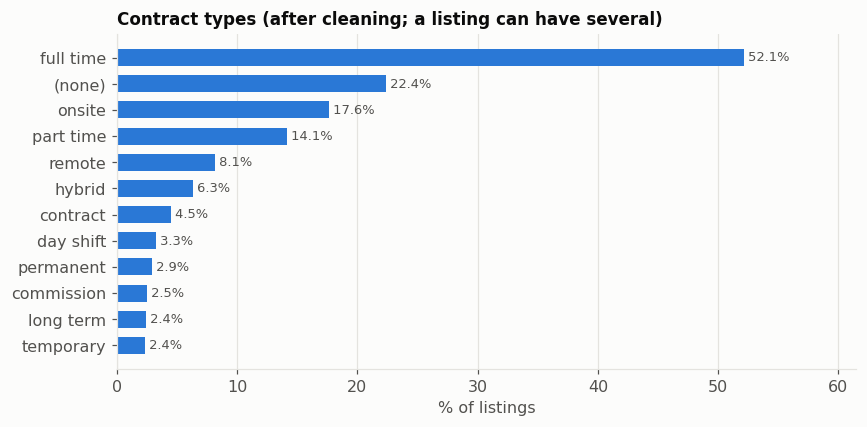

In [75]:
# 8 chart: contract types
fig, ax = plt.subplots(figsize=(8, 4))
ct = jo.contract_types.map(as_list).explode().fillna("(none)").value_counts().head(12)
bar_h(ax, 100 * ct / len(jo), "Contract types (after cleaning; a listing can have several)", "% of listings", "{:.1f}%")
finish()

**What the data shows**
- **English covers 92.3% of listings.** An English-only corpus loses little.
- **`status` holds only "closed" or nothing,** so it can't serve as a live flag (see 6.2).
- **Contract types needed cleaning:** "full_time" and "full time" were separate labels, and are now merged in 6.2. Full time is the most common type. Onsite, remote and hybrid also appear here, which gives a second remote signal alongside the text flag.
- **`tags` are too sparse to use as skills:** 53% of listings have none, and they hold 7,196 distinct values. **`categories` is a clean 27-value taxonomy** filled for 99% of listings.
- **Every job opening's company is in the companies table (100%),** so company details are always available.

## 9. Findings: where to narrow down

**Q1, which factors drive prioritization**

| Factor | Evidence | Verdict |
|---|---|---|
| Competition: company hiring volume | Listings at 20+ listing companies close in a median 14 days vs. 32 for one-off listings; these companies post 42% of listings | **Strongest factor:** model it first |
| Source | Median days open from 15 (SmartRecruiters), 17 (LinkedIn) and 19 (company sites) to 37 (BambooHR); 66% vs. 82–89% still open after a week | **Strong:** model it with company volume, since the two overlap |
| Still open / apply-by | 28% gone in 7 days, median about 22 days; 22–34% gone in the first week, depending on occupation group | **Strong:** the basis for apply-by estimates; occupation group-specific |
| Employer intent (text) | Long descriptions, urgency wording and remote mentions all go with longer windows (5–12 points at 7 days) | **Promising:** needs a multivariate model to separate it from source and size |
| Pay | Disclosed for 43%; disclosure goes with longer windows (78% vs. 67% open at 7 days); medians range $38k–$137.5k by occupation group | **Useful:** as a value factor, and disclosure as a timing signal |
| Competition: reposts | 2.1% overall, but 3–9% in food preparation, transportation and sales | **Segment-dependent:** strong only in high-turnover fields |
| Freshness | `first_seen` lags `posted` by a median 1.5 days | **Reliable** for every listing |
| Fit | Needs an applicant's résumé | Not testable in the EDA |

**Q2, what time information prioritization can rely on**
- **Posting age:** fully supported, for apply-by and freshness, on every listing.
- **Day of week:** only through `posted` (41% of listings, read as Central European dates). `first_seen` weekdays follow the crawler (Friday peak).
- **Seasonal context:** not supported, with only six months of history. It needs older snapshots from PredictLeads.

**Q3, segment**
- The segment is an **occupation group in the United States**, since every listing with a country is US.
- **Recommended:** computer and mathematical (US) for depth, with healthcare practitioners as the robustness check. Team decision pending.

**Cleaning notes for the write-up**
- 200,000 listings in; no rows removed. The timeline fields had no errors.
- 5,454 placeholder or impossible `posted` dates blanked, 4,199 reposts flagged, 14 salary outliers blanked, and `contract_types` spellings unified.
- 195,801 original listings analysed; 42,399 still open at the snapshot.
- **Data quirks to report:** `status` never says "open"; the data covers a six-month window; `posted` is stored as Central European midnight; `tags` are sparse.

**Next steps: the in-depth analysis**
1. Confirm the segment with the team, then re-run Q1 inside it.
2. **Survival model** (`lifelines` Cox regression) for days open, with company volume, source, pay disclosure and text features together. This separates the overlapping factors from Q1c–Q1f.
3. **Text features:** TF-IDF on titles and descriptions, tested as predictors of closing within 7 days, trained on earlier months and tested on later ones, with folds grouped by company.
4. **A first prioritization score** combining chance still open, company volume, source, pay and repost signals, compared with a newest-first ranking on a later time period.
5. Ask PredictLeads for older snapshots (seasonality), confirmation of the `posted` time zone, and what `status` means.